In [1]:
from utils import load_counties, load_cbsa, set_plot_style, classify_per_window
import numpy as np
import pandas as pd
import geopandas as gpd

import matplotlib.pyplot as plt
import seaborn as sns

from adjustText import adjust_text

import matplotlib.patches as mpatches
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from matplotlib.colors import LogNorm
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import LogLocator, ScalarFormatter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib as mpl

In [2]:
set_plot_style()

In [3]:
counties = load_counties()

In [4]:
### Flows and PageRanks - all combined (2011-2022)

hits_exp_all = pd.read_parquet("../data_generated/network_metrics/hits_exp_1122.parquet")
flows_exp_all = pd.read_parquet("../data_generated/network_metrics/flows_exp_1122.parquet")

hits_soc2_all = pd.read_parquet("../data_generated/network_metrics/hits_soc2_1122.parquet")
flows_soc2_all = pd.read_parquet("../data_generated/network_metrics/flows_soc2_1122.parquet")

hits_irs_all = pd.read_parquet("../data_generated/network_metrics/hits_irs_1122.parquet")
flows_irs_all = pd.read_parquet("../data_generated/network_metrics/flows_irs_1122.parquet")

hits_senior_all = pd.read_parquet("../data_generated/network_metrics/hits_seniority_1122.parquet")
flows_senior_all = pd.read_parquet("../data_generated/network_metrics/flows_seniority_1122.parquet")

## Counties

In [5]:
hits_merged=hits_exp_all.merge(hits_irs_all, on='STCOFIPS', how='inner', suffixes=('_exp', '_irs'))
hits_merged = classify_per_window(df=hits_merged, centrality="pagerank")

counties=counties.merge(hits_merged[['STCOFIPS', 'd']], on='STCOFIPS', how='left')

In [6]:
counties.sort_values("d", ascending=False).head(30)['name']

1612            Falls Church, VA
1260           San Francisco, CA
47                 San Mateo, CA
48               Santa Clara, CA
2121                 Fairfax, VA
989                 New York, NY
1036                    King, WA
272                  Suffolk, MA
3161              Williamson, TN
50                   Boulder, CO
1897              Broomfield, CO
73                    Fulton, GA
1235                  Howard, MD
1849                   Banks, GA
659                Fairfield, CT
343                Middlesex, MA
57      District of Columbia, DC
580                   Travis, TX
2075               Arlington, VA
1111                 Fairfax, VA
1211                   Marin, CA
468                   Denver, CO
239                  Chester, PA
449                 Somerset, NJ
1696               St. Louis, MO
294                     Utah, UT
37                   Alameda, CA
388                Habersham, GA
2095                  Dallas, TX
461            Santa Barbara, CA
Name: name

In [7]:
counties.sort_values("d", ascending=True).head(30)['name']

2833             Bronx, NY
308            Roanoke, VA
3028            Peoria, IL
1878           Randall, TX
1256           Clayton, GA
169             Queens, NY
366     Cape Girardeau, MO
2220            Putnam, WV
1622             Sarpy, NE
1860           Warrick, IN
189               Cass, ND
1607          Harrison, MS
629            Raleigh, WV
3086         Christian, MO
2376            Saline, AR
2820          Woodbury, IA
685              Floyd, KY
901            Bossier, LA
545             Rankin, MS
1432    Prince William, VA
1654             Ellis, KS
2359             Lamar, MS
1230             Pinal, AZ
2910           Lincoln, SD
1431        Montgomery, TN
199            El Paso, TX
1008        Cumberland, NC
1069            Lonoke, AR
3116           Houston, GA
1002        Dorchester, SC
Name: name, dtype: object

In [8]:
hits_merged['log_pagerank_irs']=np.log(hits_merged['pagerank_irs'])

In [9]:
# Extreme PuOr (higher contrast)
colors_strong = [
    "#7f3b08",   # very deep burnt orange
    "#f2c68b",   # soft orange
    "#fcead6",   # very light near-white
    "#9678d1",   # strong lavender/purple
    "#3f007d"    # very deep purple
]

strong_puor = mcolors.LinearSegmentedColormap.from_list(
    "StrongPuOr", colors_strong, N=256
)

norm = mcolors.TwoSlopeNorm(vmin=hits_merged["d"].min(),
                            vcenter=0,
                            vmax=1)

# Top 5 brain hubs (highest d)
brain_hubs = counties.sort_values("d", ascending=False).head(7)
# Top 5 mass hubs (lowest d)
mass_hubs = counties.sort_values("d", ascending=True).head(7)

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


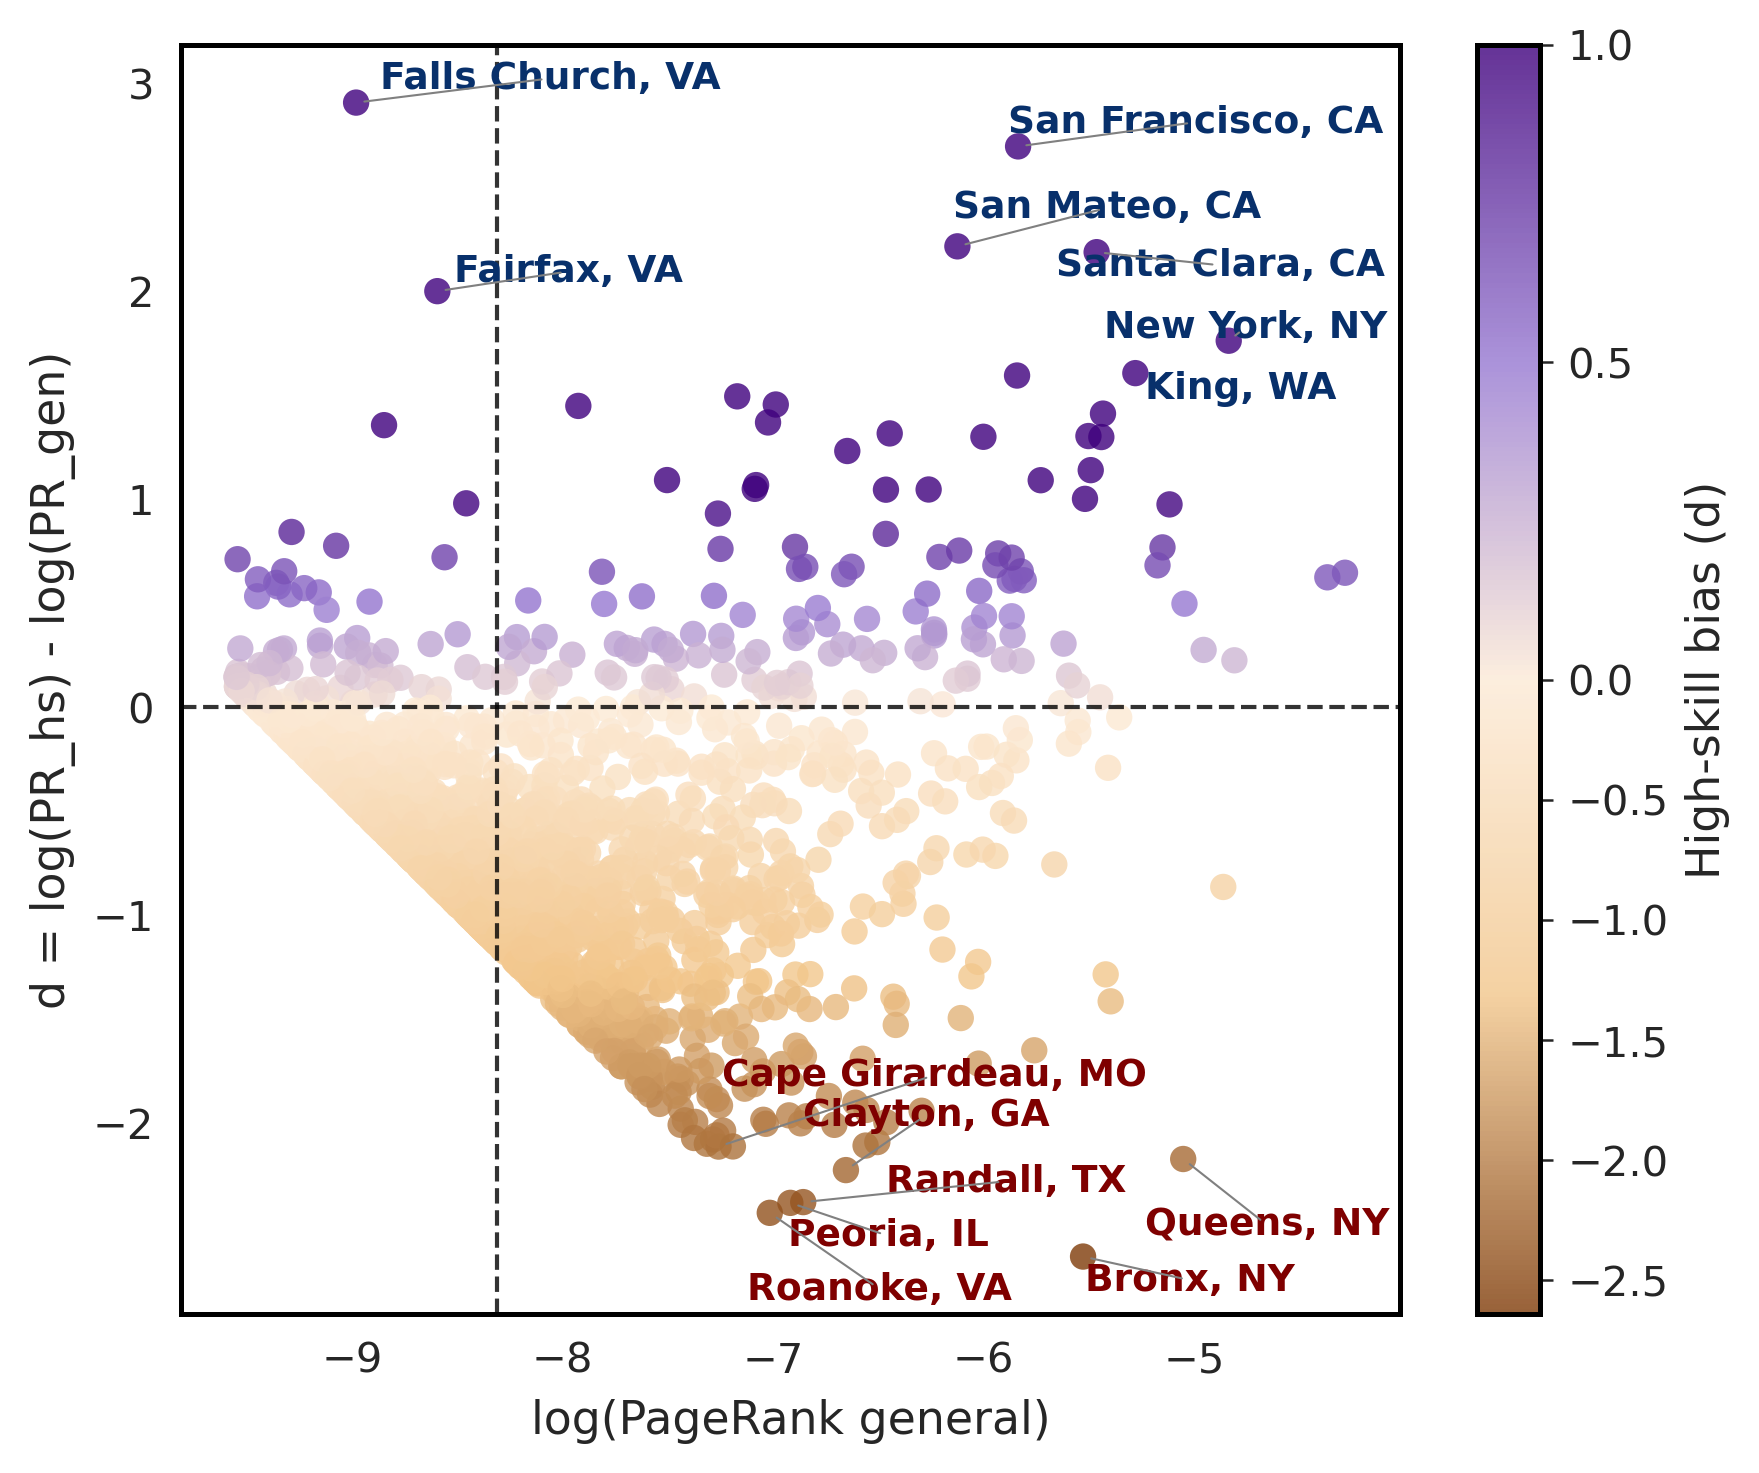

In [10]:
fig, ax = plt.subplots(figsize=(6,5))

sc = ax.scatter(
    hits_merged['log_pagerank_irs'],
    hits_merged['d'],
    c=hits_merged['d'],
    cmap=strong_puor, 
    norm=norm, 
    s=40,
    alpha=0.8,
    edgecolor="none"
)

# QUADRANT LINES
# horizontal line at d=0 (brain vs mass)
ax.axhline(0, color="black", linestyle="--", linewidth=1.0, alpha=0.8)

# vertical line at median PR (central vs peripheral)
median_pr = hits_merged['log_pagerank_irs'].median()
ax.axvline(median_pr, color="black", linestyle="--", linewidth=1.0, alpha=0.8)

ax.set_xlabel("log(PageRank general)")
ax.set_ylabel("d = log(PR_hs) - log(PR_gen)")
ax.set_title("")

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("High-skill bias (d)")

texts = []

# BRAIN HUB labels (highest d)
for _, row in brain_hubs.iterrows():
    x = hits_merged.loc[hits_merged["STCOFIPS"] == row["STCOFIPS"], "log_pagerank_irs"].values[0]
    y = hits_merged.loc[hits_merged["STCOFIPS"] == row["STCOFIPS"], "d"].values[0]

    t = ax.text(
        x, y, row["name"],
        fontsize=9, weight="bold", color="#08306B"
    )
    texts.append(t)

# MASS HUB labels (lowest d)
for _, row in mass_hubs.iterrows():
    x = hits_merged.loc[hits_merged["STCOFIPS"] == row["STCOFIPS"], "log_pagerank_irs"].values[0]
    y = hits_merged.loc[hits_merged["STCOFIPS"] == row["STCOFIPS"], "d"].values[0]

    t = ax.text(
        x, y, row["name"],
        fontsize=9, weight="bold", color="#7F0000"
    )
    texts.append(t)

# automatically adjust label positions + draw arrows
adjust_text(
    texts,
    ax=ax,
    expand_points=(2.0, 2.0),
    expand_text=(1.3, 1.3),
    arrowprops=dict(arrowstyle="-", lw=0.5, color="gray"),
    force_points=0.5,
    force_text=0.7,
)

plt.tight_layout()

plt.savefig('../fig/si/si_dualhubs.pdf', bbox_inches='tight')

plt.show()

In [11]:
hits_exp_3y = pd.read_parquet("../data_generated/network_metrics/hits_exp_3y.parquet")
hits_irs_3y = pd.read_parquet("../data_generated/network_metrics/hits_irs_3y.parquet")

hits_merged=hits_exp_3y.merge(hits_irs_3y, on=['STCOFIPS', 'window'], how='inner', suffixes=('_exp', '_irs'))

In [12]:
hits_merged["d"] = np.log(hits_merged['pagerank_exp'] + 1e-9) - np.log(hits_merged['pagerank_irs'] + 1e-9)

In [13]:
df = hits_merged[hits_merged['window'].isin(['2011-2013', '2017-2019'])]

d_pivot = df.pivot(index='STCOFIPS', columns='window', values='d')
d_pivot = d_pivot.rename(columns={
    '2011-2013': 'd_2011_2013',
    '2017-2019': 'd_2017_2019'
}).dropna().reset_index()

d_pivot['d_change'] = d_pivot['d_2017_2019'] - d_pivot['d_2011_2013']

<Axes: >

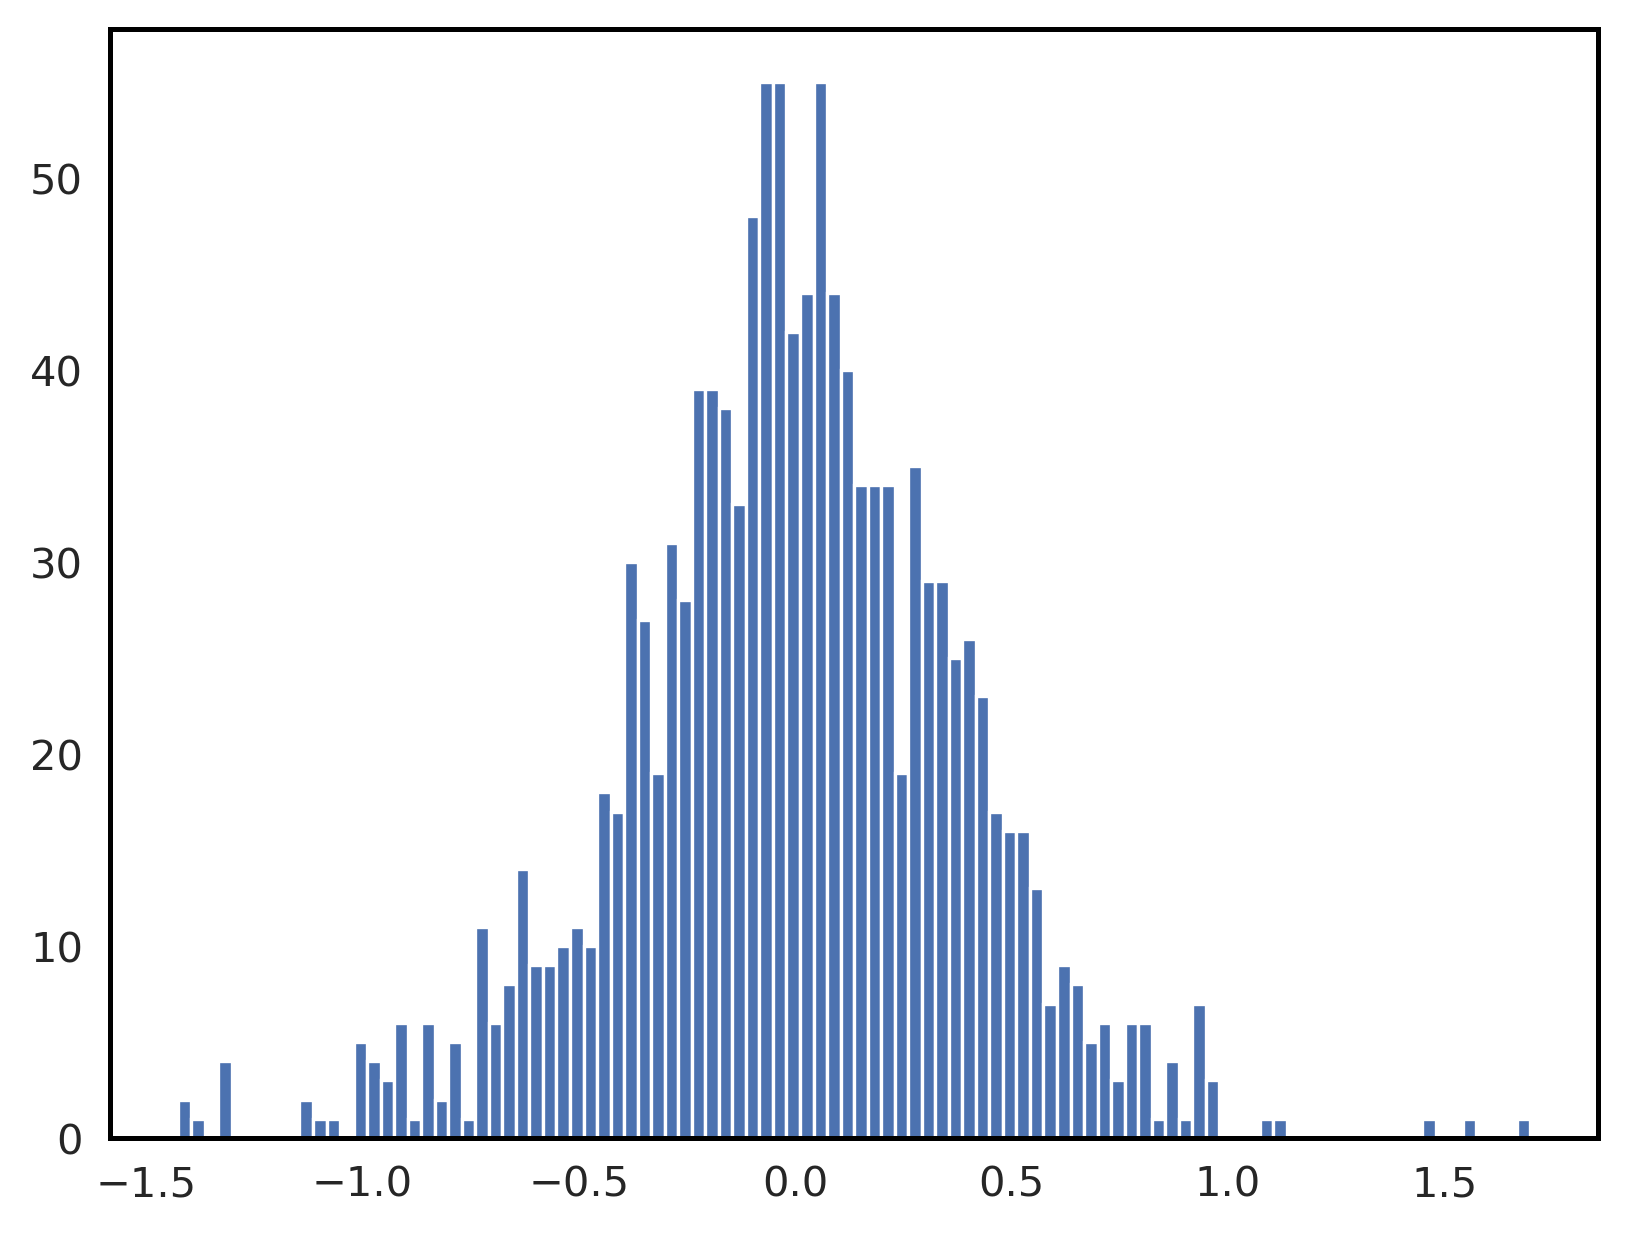

In [14]:
d_pivot.d_change.hist(bins=100)

In [15]:
d_pivot[(d_pivot['d_2011_2013']<=-0.2)&(d_pivot['d_2017_2019']>=0.2)]

window,STCOFIPS,d_2011_2013,d_2017_2019,d_change
78,06061,-0.221235,0.305714,0.526949
97,06109,-0.236801,0.238039,0.474841
148,12057,-0.249619,0.344091,0.593710
149,12061,-0.636081,0.303004,0.939086
218,13275,-0.368223,0.465914,0.834138
461,24037,-0.597814,0.213157,0.810971
612,30031,-0.214730,0.213457,0.428187
637,32031,-0.215482,0.495637,0.711119
861,40123,-0.531795,0.271924,0.803719
880,41061,-0.476714,0.277929,0.754643


In [16]:
d_pivot[(d_pivot['d_2011_2013']>=0.2)&(d_pivot['d_2017_2019']<=-0.2)]

window,STCOFIPS,d_2011_2013,d_2017_2019,d_change
213,13237,0.321320,-0.631072,-0.952393
329,19021,0.482009,-0.844052,-1.326061
332,19055,0.340901,-0.754546,-1.095447
464,24045,0.321376,-0.207690,-0.529066
722,36109,0.349955,-0.205071,-0.555026
763,37125,0.614114,-0.782118,-1.396231
796,39009,0.222732,-0.296979,-0.519711
845,39169,0.223023,-0.492426,-0.715450
870,41027,0.325050,-0.587904,-0.912954
976,46079,0.208483,-1.218458,-1.426940


In [17]:
d_pivot=d_pivot.merge(counties[['STCOFIPS', 'name']])

group_b = d_pivot[(d_pivot['d_2011_2013'] <= -0.2) &
                  (d_pivot['d_2017_2019'] >=  0.2)].copy()

group_a = d_pivot[(d_pivot['d_2011_2013'] >=  0.2) &
                  (d_pivot['d_2017_2019'] <= -0.2)].copy()


cols = ['name', 'd_2011_2013', 'd_2017_2019', 'd_change']
group_a = group_a[cols].sort_values('d_change', ascending=False)
group_b = group_b[cols].sort_values('d_change', ascending=True)


norm = mcolors.Normalize(vmin=-1, vmax=1)
cmap = plt.get_cmap("coolwarm")

In [18]:
counties=counties.merge(d_pivot[['STCOFIPS', 'd_change']], on='STCOFIPS', how='left')

In [19]:
# -------------------------------------------------------
# Split counties into regions
# -------------------------------------------------------

not_conus=['02',  # Alaska
             '15',  # Hawaii
             '72',  # Puerto Rico
             '78',  # U.S. Virgin Islands
             '60',  # American Samoa
             '66',  # Guam
             '69']  # Northern Mariana Islands

usa = counties.to_crs("EPSG:5070") 
counties = counties.to_crs("EPSG:4269")

conus = usa[~usa["STATEFP"].isin(not_conus)]
alaska = counties[counties["STATEFP"] == "02"].copy()
hawaii = counties[counties["STATEFP"] == "15"].copy()

# Background polygons
counties = counties.to_crs("EPSG:5070")
conus_outline = counties[~counties["STATEFP"].isin(not_conus)][["geometry"]].dissolve()
counties = counties.to_crs("EPSG:4269")
alaska_outline = counties[counties["STATEFP"] == "02"][["geometry"]].dissolve()
hawaii_outline = counties[counties["STATEFP"] == "15"][["geometry"]].dissolve()

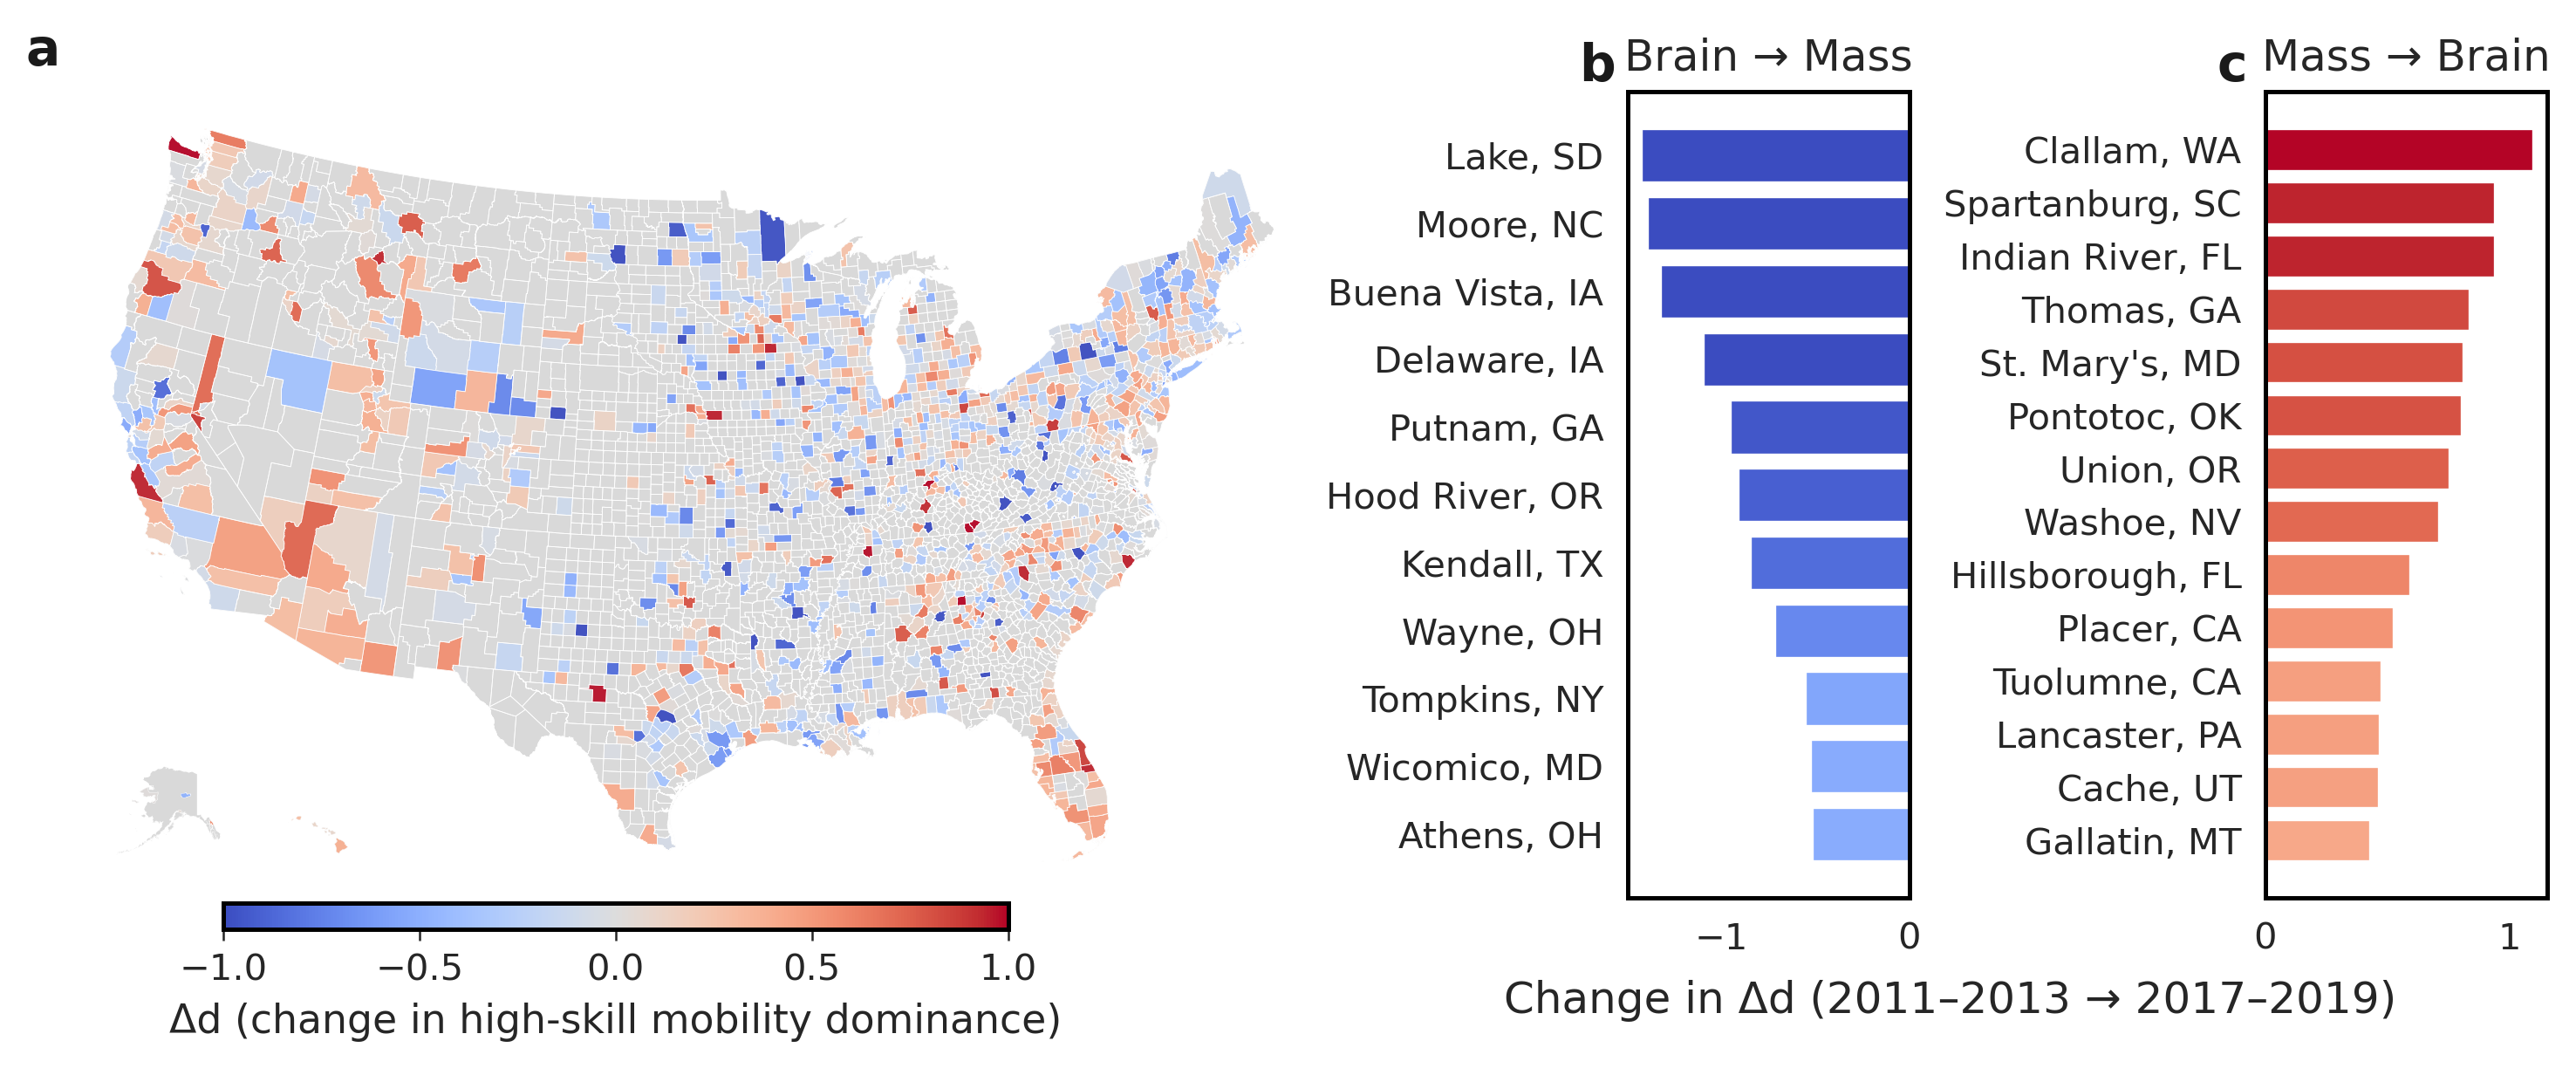

In [20]:
# colormap
norm = mcolors.Normalize(vmin=-1, vmax=1)
cmap = mpl.colormaps["coolwarm"]

# figure layout
fig, axes = plt.subplots(
    1, 3,
    figsize=(12, 4),
    gridspec_kw={"width_ratios": [5, 1, 1]},
    constrained_layout=False
)

fig.subplots_adjust(
    wspace=0.35    # increase horizontal spacing
)

ax_map = axes[0]
ax_barA = axes[1]
ax_barB = axes[2]

# ======================================================
#  MAIN CONUS MAP
# ======================================================

conus_outline.plot(
    color="#d9d9d9",
    linewidth=0,
    ax=ax_map,
    zorder=1,
    rasterized=True
)

conus.plot(
    column='d_change',
    cmap=cmap,
    norm=norm,
    linewidth=0.2,
    edgecolor='white',
    ax=ax_map,
    legend=False,
    alpha=0.95,
    zorder=2,
    missing_kwds={"color": "none"},
    rasterized=True
)

ax_map.axis("off")
ax_map.set_title("")

# -------------------------------
# Alaska inset
# -------------------------------
ax_ak = inset_axes(
    ax_map, width="38%", height="38%",
    loc="lower left",
    bbox_to_anchor=(0.02, 0.03, 0.3, 0.3),
    bbox_transform=ax_map.transAxes
)
ax_ak.axis("off")

alaska_outline.plot(color="#d9d9d9", linewidth=0, ax=ax_ak, rasterized=True)
alaska.plot(
    column='d_change',
    cmap=cmap,
    norm=norm,
    linewidth=0.1,
    edgecolor="white",
    ax=ax_ak,
    alpha=0.95,
    rasterized=True
)
ax_ak.set_xlim(-180, -129)
ax_ak.set_ylim(51, 72)

# -------------------------------
# Hawaii inset
# -------------------------------
ax_hi = inset_axes(
    ax_map, width="28%", height="28%",
    loc="lower left",
    bbox_to_anchor=(0.16, 0.02, 0.25, 0.25),
    bbox_transform=ax_map.transAxes
)
ax_hi.axis("off")

hawaii_outline.plot(color="#d9d9d9", linewidth=0, ax=ax_hi, rasterized=True)
hawaii.plot(
    column='d_change',
    cmap=cmap,
    norm=norm,
    linewidth=0.1,
    edgecolor="white",
    ax=ax_hi,
    alpha=0.95,
    rasterized=True
)
ax_hi.set_xlim(-161, -154)
ax_hi.set_ylim(18, 23)


# ======================================================
# BARPLOT A (MASS → BRAIN)
# ======================================================

ax_barA.barh(
    group_a['name'],
    group_a['d_change'],
    color=cmap(norm(group_a['d_change']))
)
ax_barA.set_title("Brain → Mass")
ax_barA.set_xlabel("")


# ======================================================
# BARPLOT B (BRAIN → MASS)
# ======================================================

ax_barB.barh(
    group_b['name'],
    group_b['d_change'],
    color=cmap(norm(group_b['d_change']))
)
ax_barB.set_title("Mass → Brain")
ax_barB.set_xlabel("")


# get positions
posA = axes[1].get_position()
posB = axes[2].get_position()

# shift B right by +0.04 (adjust as needed)
axes[2].set_position([
    posB.x0 + 0.04,
    posB.y0,
    posB.width,
    posB.height
])

# SHARED X-LABEL FOR BARPLOTS ONLY
fig.text(
    0.75,       # horizontal center of barplots A+B
    0,       # vertical position (adjust)
    "Change in Δd (2011–2013 → 2017–2019)",
    ha='center',
    fontsize=12
)

# SHARED COLORBAR FOR ALL THREE SUBPLOTS
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar_ax = fig.add_axes([0.2, 0.08, 0.25, 0.025])

cbar = fig.colorbar(
    sm,
    cax=cbar_ax,
    orientation="horizontal",
    fraction=0.06,
    pad=0.12
)
cbar.set_label("Δd (change in high-skill mobility dominance)")

plots_l = ['a', 'b', 'c']

for ia, ax in enumerate(axes):
    x = -0.02
    y = 1.02

    if ia == 1:
        x = -0.17 
        y = 1
    elif ia == 2:
        x = -0.17 
        y = 1

    ax.text(
        x, y,
        plots_l[ia],
        color='k',
        ha='left',
        va='bottom',
        weight='bold',
        transform=ax.transAxes,
        fontsize=14
    )


plt.savefig(
    '../fig/si/si_pagerank_tempchanges.png',
    bbox_inches='tight',
    dpi=300
)

plt.show()


In [21]:
hits_soc2_all=hits_soc2_all.merge(counties[['STCOFIPS', 'name']])

In [22]:
# Make a copy so nothing gets overwritten
df = hits_soc2_all.copy()

# For safety, ensure pagerank is numeric
df["pagerank"] = pd.to_numeric(df["pagerank"], errors="coerce")

# Sort descending within each field and take top 20
top20 = (
    df.sort_values(["job_field", "pagerank"], ascending=[True, False])
      .groupby("job_field")
      .head(20)
)

# Create rank within each job field (1 = highest PageRank)
top20["rank_within_field"] = top20.groupby("job_field")["pagerank"].rank(
    method="first", ascending=False
).astype(int)

# Pivot into a wide table (columns = job fields, rows = 1..20)
table = (
    top20.pivot(
        index="rank_within_field",
        columns="job_field",
        values="name"   # or use df["name"] if you add names
    )
    .sort_index()
)

# (Optional) sort columns alphabetically
table = table.reindex(sorted(table.columns), axis=1)

table


job_field,Architecture & Engineering,Arts / Media / Design,Business & Finance,Computer & Math,Education / Training,Healthcare Practitioners,Legal,Management,Sales,Sciences,Social Services
rank_within_field,,,,,,,,,,,
1,"Santa Clara, CA","New York, NY","New York, NY","San Francisco, CA","San Francisco, CA","Dallas, TX","New York, NY","New York, NY","New York, NY","San Francisco, CA","Los Angeles, CA"
2,"San Francisco, CA","Los Angeles, CA","Cook, IL","Santa Clara, CA","New York, NY","Cook, IL","District of Columbia, DC","San Francisco, CA","San Francisco, CA","Los Angeles, CA","Santa Clara, CA"
3,"New York, NY","San Francisco, CA","Los Angeles, CA","New York, NY","Santa Clara, CA","New York, NY","Cook, IL","Santa Clara, CA","Los Angeles, CA","New York, NY","San Diego, CA"
4,"San Mateo, CA","Cook, IL","Dallas, TX","King, WA","Los Angeles, CA","Los Angeles, CA","Los Angeles, CA","Cook, IL","Santa Clara, CA","Suffolk, MA","New York, NY"
5,"Los Angeles, CA","Fulton, GA","San Mateo, CA","San Mateo, CA","King, WA","Fulton, GA","San Francisco, CA","Los Angeles, CA","Cook, IL","Dallas, TX","Cook, IL"
6,"King, WA","Suffolk, MA","San Francisco, CA","Los Angeles, CA","Cook, IL","San Diego, CA","Fulton, GA","Fulton, GA","Fulton, GA","Santa Clara, CA","San Francisco, CA"
7,"Middlesex, MA","Dallas, TX","Fulton, GA","Fairfax, VA","San Mateo, CA","Orange, CA","Dallas, TX","Dallas, TX","Travis, TX","King, WA","District of Columbia, DC"
8,"Alameda, CA","Santa Clara, CA","Santa Clara, CA","Cook, IL","Middlesex, MA","Maricopa, AZ","Santa Clara, CA","Travis, TX","Middlesex, MA","San Mateo, CA","Alameda, CA"
9,"Fulton, GA","King, WA","King, WA","Travis, TX","District of Columbia, DC","Davidson, TN","Orange, CA","King, WA","Dallas, TX","Middlesex, MA","Fulton, GA"


In [23]:
df_wide = hits_soc2_all.pivot_table(
    index="STCOFIPS",
    columns="job_field",
    values="pagerank"
)

df_wide = df_wide.dropna()

corr_spearman = df_wide.corr(method="spearman")


In [24]:
corr_spearman.round(2)


job_field,Architecture & Engineering,Arts / Media / Design,Business & Finance,Computer & Math,Education / Training,Healthcare Practitioners,Legal,Management,Sales,Sciences,Social Services
job_field,,,,,,,,,,,
Architecture & Engineering,1.00,0.78,0.77,0.82,0.82,0.61,0.60,0.78,0.74,0.59,0.48
Arts / Media / Design,0.78,1.00,0.91,0.89,0.91,0.77,0.64,0.92,0.87,0.64,0.58
Business & Finance,0.77,0.91,1.00,0.90,0.90,0.79,0.67,0.96,0.90,0.64,0.61
Computer & Math,0.82,0.89,0.90,1.00,0.90,0.71,0.67,0.91,0.84,0.68,0.59
Education / Training,0.82,0.91,0.90,0.90,1.00,0.73,0.68,0.91,0.84,0.68,0.58
Healthcare Practitioners,0.61,0.77,0.79,0.71,0.73,1.00,0.56,0.79,0.75,0.56,0.54
Legal,0.60,0.64,0.67,0.67,0.68,0.56,1.00,0.67,0.63,0.58,0.50
Management,0.78,0.92,0.96,0.91,0.91,0.79,0.67,1.00,0.94,0.66,0.60
Sales,0.74,0.87,0.90,0.84,0.84,0.75,0.63,0.94,1.00,0.65,0.58


In [25]:
def format_bottom_colorbar(cbar, label):
    # identical tick behaviour
    cbar.ax.tick_params(
        axis="x",
        labelsize=9,
        length=4,
        width=0.6,
        pad=3
    )

    # identical label formatting
    cbar.set_label(label, fontsize=10, labelpad=4)

    # identical spine appearance
    for side in ["bottom", "top"]:
        cbar.ax.spines[side].set_visible(True)
        cbar.ax.spines[side].set_linewidth(0.6)

    # no left/right spines (keeps consistent)
    cbar.ax.spines["left"].set_visible(False)
    cbar.ax.spines["right"].set_visible(False)

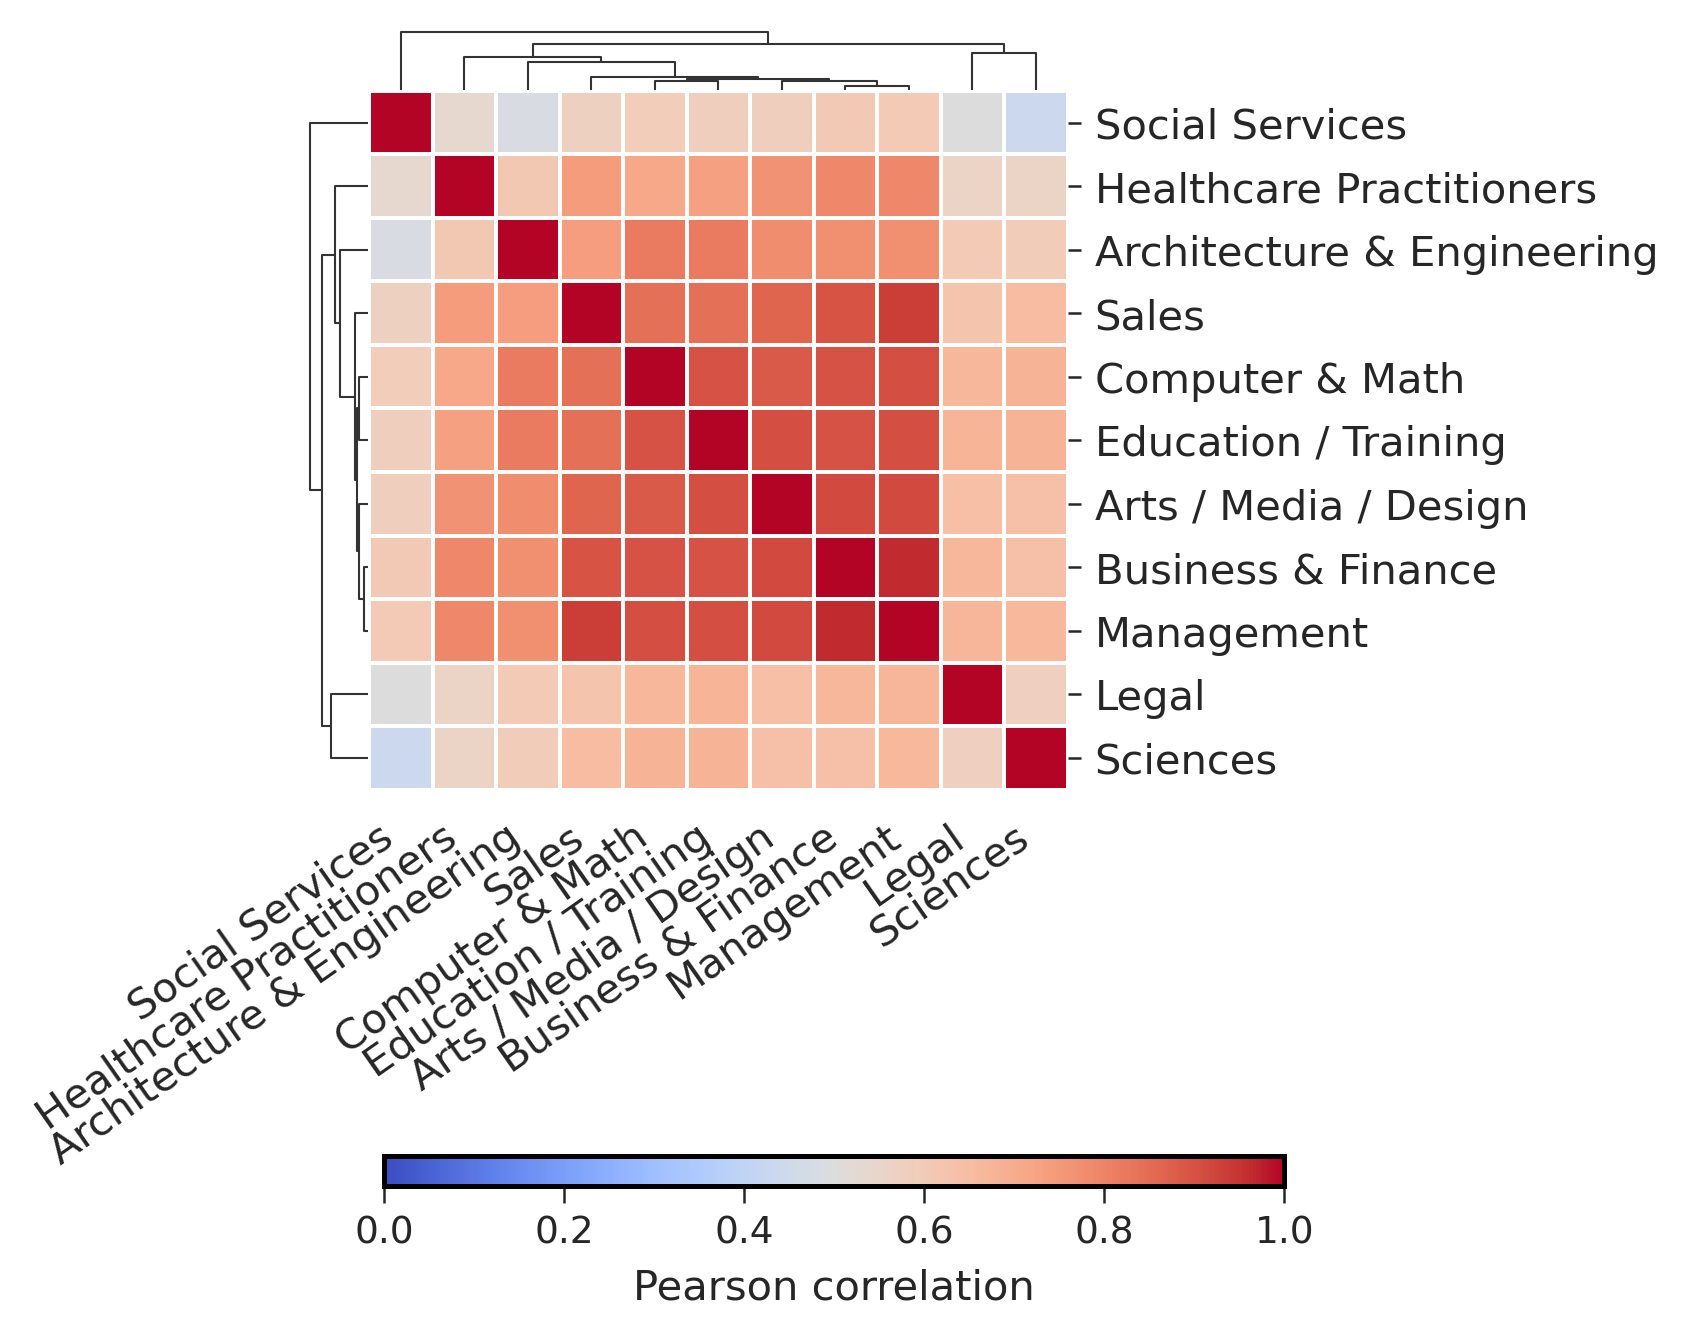

In [26]:
g = sns.clustermap(
    corr_spearman,
    cmap="coolwarm",
    method="average", 
    metric="euclidean",
    linewidths=0.5,
    figsize=(5, 5),
    vmin=0, vmax=1,
    annot=False,
    cbar_pos=None,
    dendrogram_ratio=(0.08, 0.08),
)

fig = g.fig

left = 0.08
width = 0.6
bottom = 0.2
height = 0.02
cax = fig.add_axes([left, bottom, width, height])

# Pearson ScalarMappable
pearson_norm = plt.Normalize(vmin=0, vmax=1)
sm = plt.cm.ScalarMappable(norm=pearson_norm, cmap="coolwarm")

g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xmajorticklabels(), rotation=35, ha="right")
g.ax_heatmap.set_xlabel("")
g.ax_heatmap.set_ylabel("")

cbar = fig.colorbar(
    sm,
    cax=cax,
    orientation="horizontal",
)
format_bottom_colorbar(cbar, "Pearson correlation")

plt.savefig(
    '../fig/si/si_jobfields_corr.pdf',
    bbox_inches='tight',
    dpi=300
)

plt.show()

## CBSA

In [27]:
counties = load_counties()

In [28]:
hits_exp_all = pd.read_parquet("../data_generated/network_metrics/cbsa2_hits_exp_1122.parquet")
hits_irs_all = pd.read_parquet("../data_generated/network_metrics/cbsa2_hits_irs_1122.parquet")
hits_soc2_all = pd.read_parquet("../data_generated/network_metrics/cbsa2_soc2_hits_exp_1122.parquet")
hits_senior_all = pd.read_parquet("../data_generated/network_metrics/cbsa2_seniority_hits_exp_1122.parquet")

cbsa = load_cbsa()

In [29]:
counties=counties.merge(cbsa[['CBSA Code', 'CBSA Title', 'STCOFIPS']], on='STCOFIPS', how='left')

cbsa_gdf = counties.dissolve(
    by='CBSA Code',
    as_index=False
)

cbsa_gdf=cbsa_gdf.drop(columns=['name'])
cbsa_gdf=cbsa_gdf.rename(columns={'CBSA Title':'name', 'CBSA Code':'CBSA'})

In [30]:
hits_merged=hits_exp_all.merge(hits_irs_all, on='CBSA', how='inner', suffixes=('_exp', '_irs'))
hits_merged = classify_per_window(df=hits_merged, centrality="pagerank")

cbsa_gdf=cbsa_gdf.merge(hits_merged[['CBSA', 'd']], on='CBSA', how='left')

In [31]:
cbsa_gdf.sort_values("d", ascending=False).head(30)['name']

748                 San Francisco-Oakland-Fremont, CA
749                San Jose-Sunnyvale-Santa Clara, CA
58                   Austin-Round Rock-San Marcos, TX
764                       Seattle-Tacoma-Bellevue, WA
104                    Boston-Cambridge-Newton, MA-NH
886      Washington-Arlington-Alexandria, DC-VA-MD-WV
224                      Denver-Aurora-Centennial, CO
604                New York-Newark-Jersey City, NY-NJ
687                               Provo-Orem-Lehi, UT
50                  Atlanta-Sandy Springs-Roswell, GA
592    Nashville-Davidson--Murfreesboro--Franklin, TN
105                                       Boulder, CO
704                                      Richmond, VA
164                              Cincinnati, OH-KY-IN
552           Minneapolis-St. Paul-Bloomington, MN-WI
102                                         Boone, NC
209                   Dallas-Fort Worth-Arlington, TX
734                                  St. Louis, MO-IL
157                 Charlott

In [32]:
cbsa_gdf.sort_values("d", ascending=True).head(30)['name']

262                             El Paso, TX
436                      Killeen-Temple, TX
857                      Urban Honolulu, HI
167                      Clarksville, TN-KY
282                        Fayetteville, NC
351                     Gulfport-Biloxi, MS
388            Huntington-Ashland, WV-KY-OH
61                   Bakersfield-Delano, CA
531            McAllen-Edinburg-Mission, TX
120               Brownsville-Harlingen, TX
708    Riverside-San Bernardino-Ontario, CA
639                               Ozark, AL
289                               Flint, MI
281                          Farmington, NM
891                 Watertown-Fort Drum, NY
406                        Jacksonville, NC
381                         Hot Springs, AR
31                       Anderson Creek, NC
154                          Charleston, WV
816                       Stockton-Lodi, CA
560                              Monroe, MI
470                              Lawton, OK
529                            M

In [33]:
hits_merged['log_pagerank_irs']=np.log(hits_merged['pagerank_irs'])

In [34]:
# Extreme PuOr (higher contrast)
colors_strong = [
    "#7f3b08",   # very deep burnt orange
    "#f2c68b",   # soft orange
    "#fcead6",   # very light near-white
    "#9678d1",   # strong lavender/purple
    "#3f007d"    # very deep purple
]

strong_puor = mcolors.LinearSegmentedColormap.from_list(
    "StrongPuOr", colors_strong, N=256
)

norm = mcolors.TwoSlopeNorm(vmin=hits_merged["d"].min(),
                            vcenter=0,
                            vmax=1)

# Top 5 brain hubs (highest d)
brain_hubs = cbsa_gdf.sort_values("d", ascending=False).head(7)
# Top 5 mass hubs (lowest d)
mass_hubs = cbsa_gdf.sort_values("d", ascending=True).head(7)

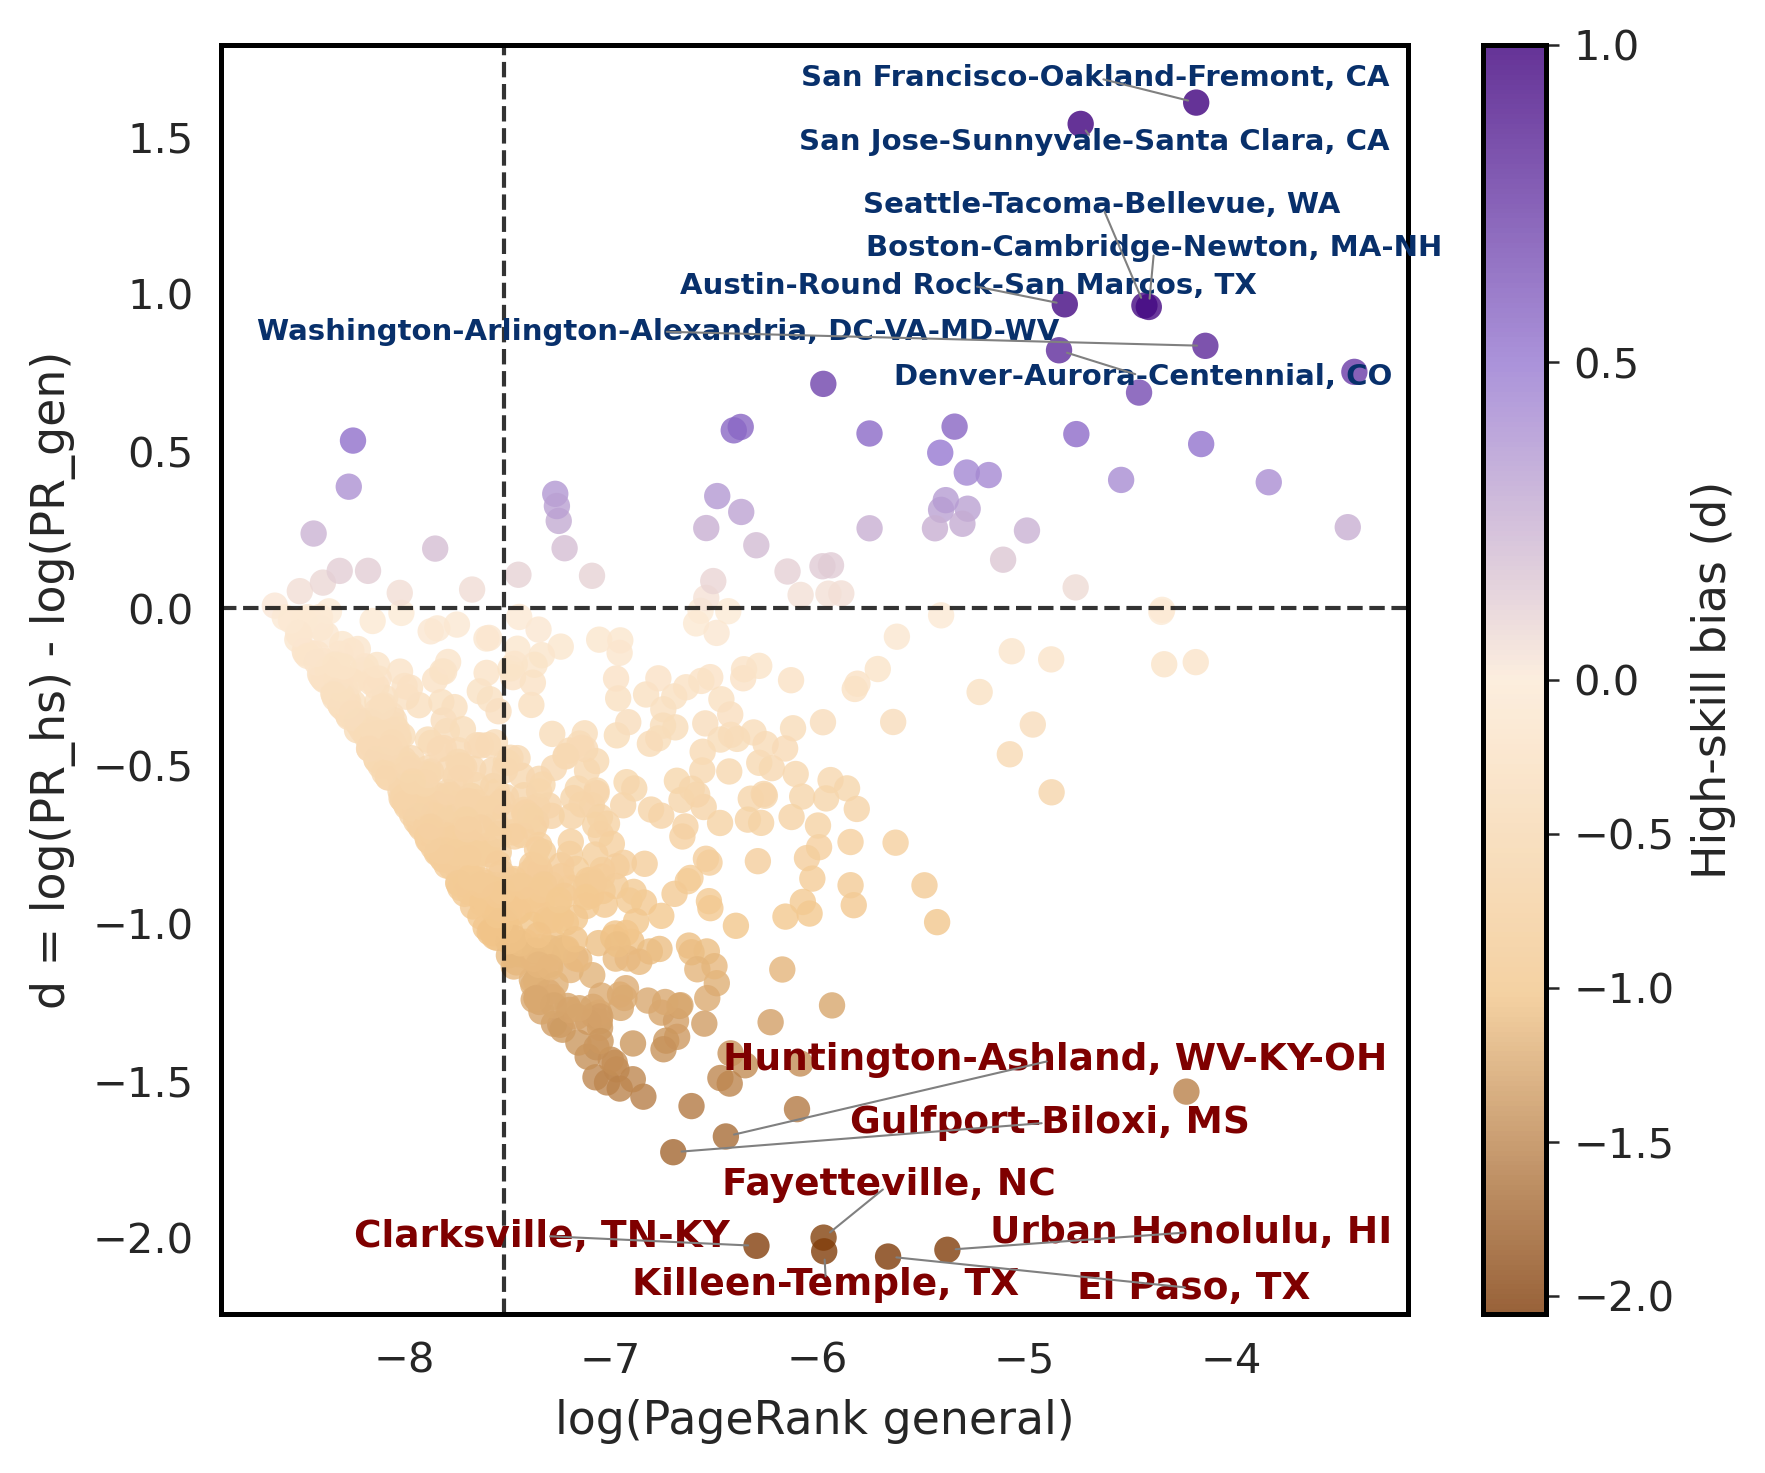

In [35]:
fig, ax = plt.subplots(figsize=(6,5))

# scatter
sc = ax.scatter(
    hits_merged['log_pagerank_irs'],
    hits_merged['d'],
    c=hits_merged['d'],
    cmap=strong_puor,  
    norm=norm,
    s=40,
    alpha=0.8,
    edgecolor="none"
)

# QUADRANT LINES
# horizontal line at d=0 (brain vs mass)
ax.axhline(0, color="black", linestyle="--", linewidth=1.0, alpha=0.8)

# vertical line at median PR (central vs peripheral)
median_pr = hits_merged['log_pagerank_irs'].median()
ax.axvline(median_pr, color="black", linestyle="--", linewidth=1.0, alpha=0.8)

ax.set_xlabel("log(PageRank general)")
ax.set_ylabel("d = log(PR_hs) - log(PR_gen)")
ax.set_title("")

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("High-skill bias (d)")

texts = []

# add BRAIN HUB labels (highest d)
for _, row in brain_hubs.iterrows():
    x = hits_merged.loc[hits_merged["CBSA"] == row["CBSA"], "log_pagerank_irs"].values[0]
    y = hits_merged.loc[hits_merged["CBSA"] == row["CBSA"], "d"].values[0]

    t = ax.text(
        x, y, row["name"],
        fontsize=7, weight="bold", color="#08306B"   # dark blue
    )
    texts.append(t)

# add MASS HUB labels (lowest d)
for _, row in mass_hubs.iterrows():
    x = hits_merged.loc[hits_merged["CBSA"] == row["CBSA"], "log_pagerank_irs"].values[0]
    y = hits_merged.loc[hits_merged["CBSA"] == row["CBSA"], "d"].values[0]

    t = ax.text(
        x, y, row["name"],
        fontsize=9, weight="bold", color="#7F0000"   # dark red
    )
    texts.append(t)

# Automatically adjust label positions + draw arrows
adjust_text(
    texts,
    ax=ax,
    expand_points=(2.0, 2.0),
    expand_text=(1.3, 1.3),
    arrowprops=dict(arrowstyle="-", lw=0.5, color="gray"),
    force_points=0.5,
    force_text=0.7,
)

plt.tight_layout()

plt.savefig('../fig/si/si_dualhubs_cbsa2.pdf', bbox_inches='tight')

plt.show()

In [36]:
hits_exp_3y = pd.read_parquet("../data_generated/network_metrics/cbsa2_hits_exp_3y.parquet")
hits_irs_3y = pd.read_parquet("../data_generated/network_metrics/cbsa2_hits_irs_3y.parquet")

hits_merged=hits_exp_3y.merge(hits_irs_3y, on=['CBSA', 'window'], how='inner', suffixes=('_exp', '_irs'))

In [37]:
hits_merged["d"] = np.log(hits_merged['pagerank_exp'] + 1e-9) - np.log(hits_merged['pagerank_irs'] + 1e-9)

In [38]:
df = hits_merged[hits_merged['window'].isin(['2011-2013', '2017-2019'])]

d_pivot = df.pivot(index='CBSA', columns='window', values='d')
d_pivot = d_pivot.rename(columns={
    '2011-2013': 'd_2011_2013',
    '2017-2019': 'd_2017_2019'
}).dropna().reset_index()

d_pivot['d_change'] = d_pivot['d_2017_2019'] - d_pivot['d_2011_2013']

<Axes: >

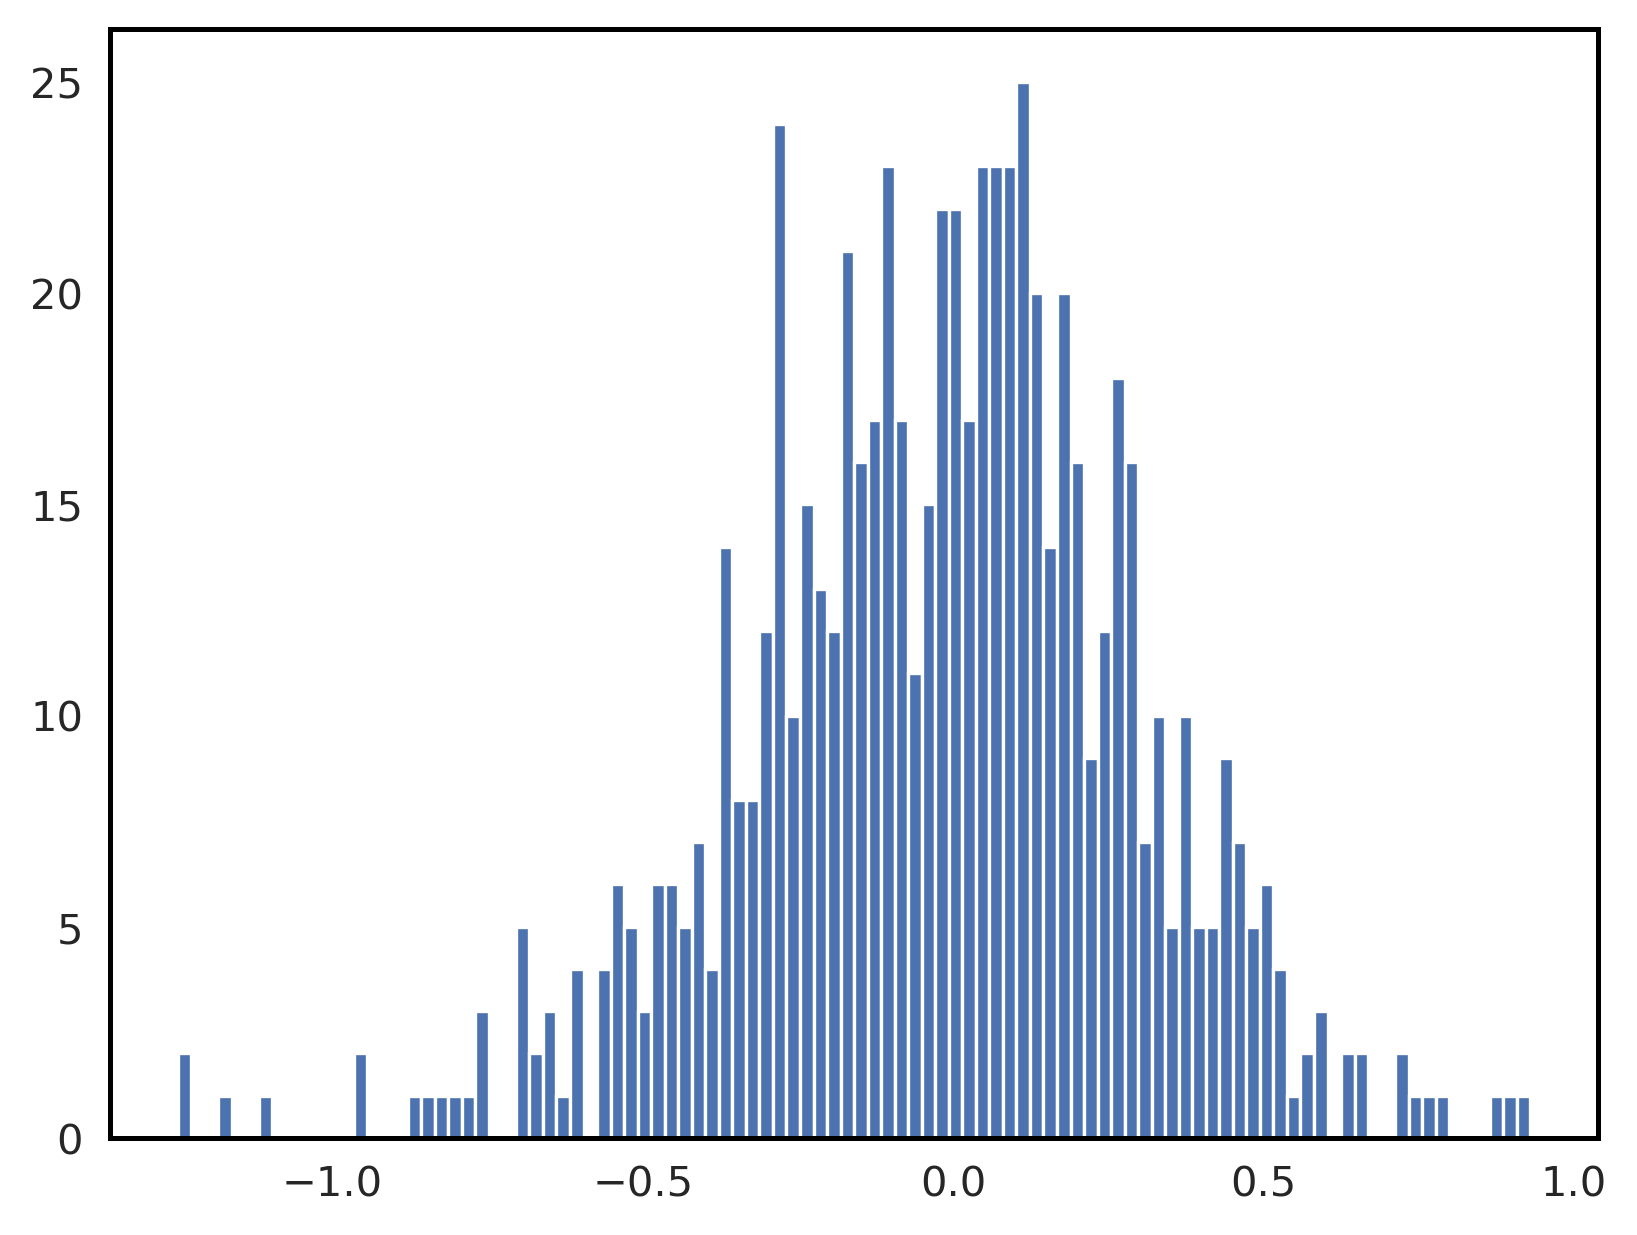

In [39]:
d_pivot.d_change.hist(bins=100)

In [40]:
d_pivot=d_pivot.merge(cbsa_gdf[['CBSA', 'name']], on='CBSA', how='left')

In [41]:
d_pivot.sort_values(['d_change'], ascending=False)['name'].head(20)

666                                 Wilmington, NC
515                                       Reno, NV
381                                     Martin, TN
59                                  Bellingham, WA
533                                   Roseburg, OR
680                                       Yuma, AZ
473              Palm Bay-Melbourne-Titusville, FL
415                                 Morristown, TN
582                           Sioux City, IA-NE-SD
203                                    Findlay, OH
567    Sebastian-Vero Beach-West Vero Corridor, FL
21                                   Anchorage, AK
602                              Stockton-Lodi, CA
219                                    Fremont, NE
116                            Charlottesville, VA
72                                  Boise City, ID
479                 Pensacola-Ferry Pass-Brent, FL
225                    Gardnerville Ranchos, NV-CA
627                                 Tuscaloosa, AL
499                            

In [42]:
d_pivot[(d_pivot['d_2011_2013']<=-0.1)&(d_pivot['d_2017_2019']>=0.1)]

,CBSA,d_2011_2013,d_2017_2019,d_change,name
59,13380,-0.574272,0.209800,0.784072,"Bellingham, WA"
72,14260,-0.274019,0.306932,0.580951,"Boise City, ID"
225,23820,-0.279451,0.276880,0.556331,"Gardnerville Ranchos, NV-CA"
289,27220,-0.138159,0.365339,0.503498,"Jackson, WY-ID"
332,29260,-0.125080,0.164978,0.290058,"La Grande, OR"
473,37340,-0.515111,0.214105,0.729216,"Palm Bay-Melbourne-Titusville, FL"
478,37800,-0.164162,0.123510,0.287671,"Pella, IA"
515,39900,-0.552843,0.337127,0.889970,"Reno, NV"
589,43900,-0.306682,0.193386,0.500068,"Spartanburg, SC"
616,45620,-0.417107,0.101076,0.518182,"Thomasville, GA"


In [43]:
d_pivot[(d_pivot['d_2011_2013']>=0.1)&(d_pivot['d_2017_2019']<=-0.1)]

,CBSA,d_2011_2013,d_2017_2019,d_change,name
31,11900,0.157356,-0.466047,-0.623404,"Athens, OH"
67,13980,0.123520,-0.360527,-0.484047,"Blacksburg-Christiansburg-Radford, VA"
69,14020,0.112169,-0.430301,-0.542471,"Bloomington, IN"
88,15100,0.181276,-0.572817,-0.754093,"Brookings, SD"
170,20260,0.204359,-0.644440,-0.848799,"Duluth, MN-WI"
183,21220,0.117070,-0.289437,-0.406507,"Elko, NV"
270,26420,0.348376,-0.341282,-0.689658,"Houston-Pasadena-The Woodlands, TX"
402,33540,0.178617,-0.334244,-0.512861,"Missoula, MT"
406,33740,0.286394,-0.253301,-0.539695,"Monroe, LA"
431,34900,0.238710,-0.440821,-0.679531,"Napa, CA"


In [44]:
d_pivot=d_pivot.merge(cbsa_gdf[['CBSA', 'name']])

group_b = d_pivot[(d_pivot['d_2011_2013'] <= -0.1) &
                  (d_pivot['d_2017_2019'] >=  0.1)].copy()

group_a = d_pivot[(d_pivot['d_2011_2013'] >=  0.1) &
                  (d_pivot['d_2017_2019'] <= -0.1)].copy()


cols = ['name', 'd_2011_2013', 'd_2017_2019', 'd_change']
group_a = group_a[cols].sort_values('d_change', ascending=False)
group_b = group_b[cols].sort_values('d_change', ascending=True)


norm = mcolors.Normalize(vmin=-0.5, vmax=0.5)
cmap = plt.get_cmap("coolwarm")

In [45]:
# now, since cbsa_gdf have for 2019 already, additionally add 2022

cbsa_gdf=cbsa_gdf.merge(d_pivot[['CBSA', 'd_change']], on='CBSA', how='left')

df = hits_merged[hits_merged['window'].isin(['2011-2013', '2020-2022'])]

d_pivot = df.pivot(index='CBSA', columns='window', values='d')
d_pivot = d_pivot.rename(columns={
    '2011-2013': 'd_2011_2013',
    '2020-2022': 'd_2020_2022'
}).dropna().reset_index()

d_pivot['d_change'] = d_pivot['d_2020_2022'] - d_pivot['d_2011_2013']
d_pivot=d_pivot.merge(cbsa_gdf[['CBSA', 'name']], on='CBSA', how='left')

cbsa_gdf=cbsa_gdf.merge(d_pivot[['CBSA', 'd_change']], on='CBSA', how='left', suffixes=('_2019', '_2022'))

In [46]:
cbsa_gdf[['d_change_2019', 'd_change_2022']].corr(method='spearman')

,d_change_2019,d_change_2022
d_change_2019,1.000000,0.539605
d_change_2022,0.539605,1.000000


In [47]:
cbsa_gdf[['d_change_2019', 'd_change_2022']].corr(method='pearson')

,d_change_2019,d_change_2022
d_change_2019,1.000000,0.559736
d_change_2022,0.559736,1.000000


In [48]:
cbsa_gdf[['d_change_2019', 'd_change_2022']].dropna()

,d_change_2019,d_change_2022
0,-0.236138,0.031702
2,-0.456142,-0.053494
3,0.307405,0.525656
4,-0.275731,-0.110700
6,0.256320,0.076332
...,...,...
922,0.292400,0.381125
923,-0.100346,0.236878
924,0.058834,-0.061162
925,0.749949,0.450850


In [49]:
# -------------------------------------------------------
# Split counties into regions
# -------------------------------------------------------

not_conus=['02',  # Alaska
             '15',  # Hawaii
             '72',  # Puerto Rico
             '78',  # U.S. Virgin Islands
             '60',  # American Samoa
             '66',  # Guam
             '69']  # Northern Mariana Islands

usa = cbsa_gdf.to_crs("EPSG:5070") 
cbsa_gdf = cbsa_gdf.to_crs("EPSG:4269")

conus = usa[~usa["STATEFP"].isin(not_conus)]
alaska = cbsa_gdf[cbsa_gdf["STATEFP"] == "02"].copy()
hawaii = cbsa_gdf[cbsa_gdf["STATEFP"] == "15"].copy()

# Background polygons
counties = counties.to_crs("EPSG:5070")
conus_outline = counties[~counties["STATEFP"].isin(not_conus)][["geometry"]].dissolve()
counties = counties.to_crs("EPSG:4269")
alaska_outline = counties[counties["STATEFP"] == "02"][["geometry"]].dissolve()
hawaii_outline = counties[counties["STATEFP"] == "15"][["geometry"]].dissolve()


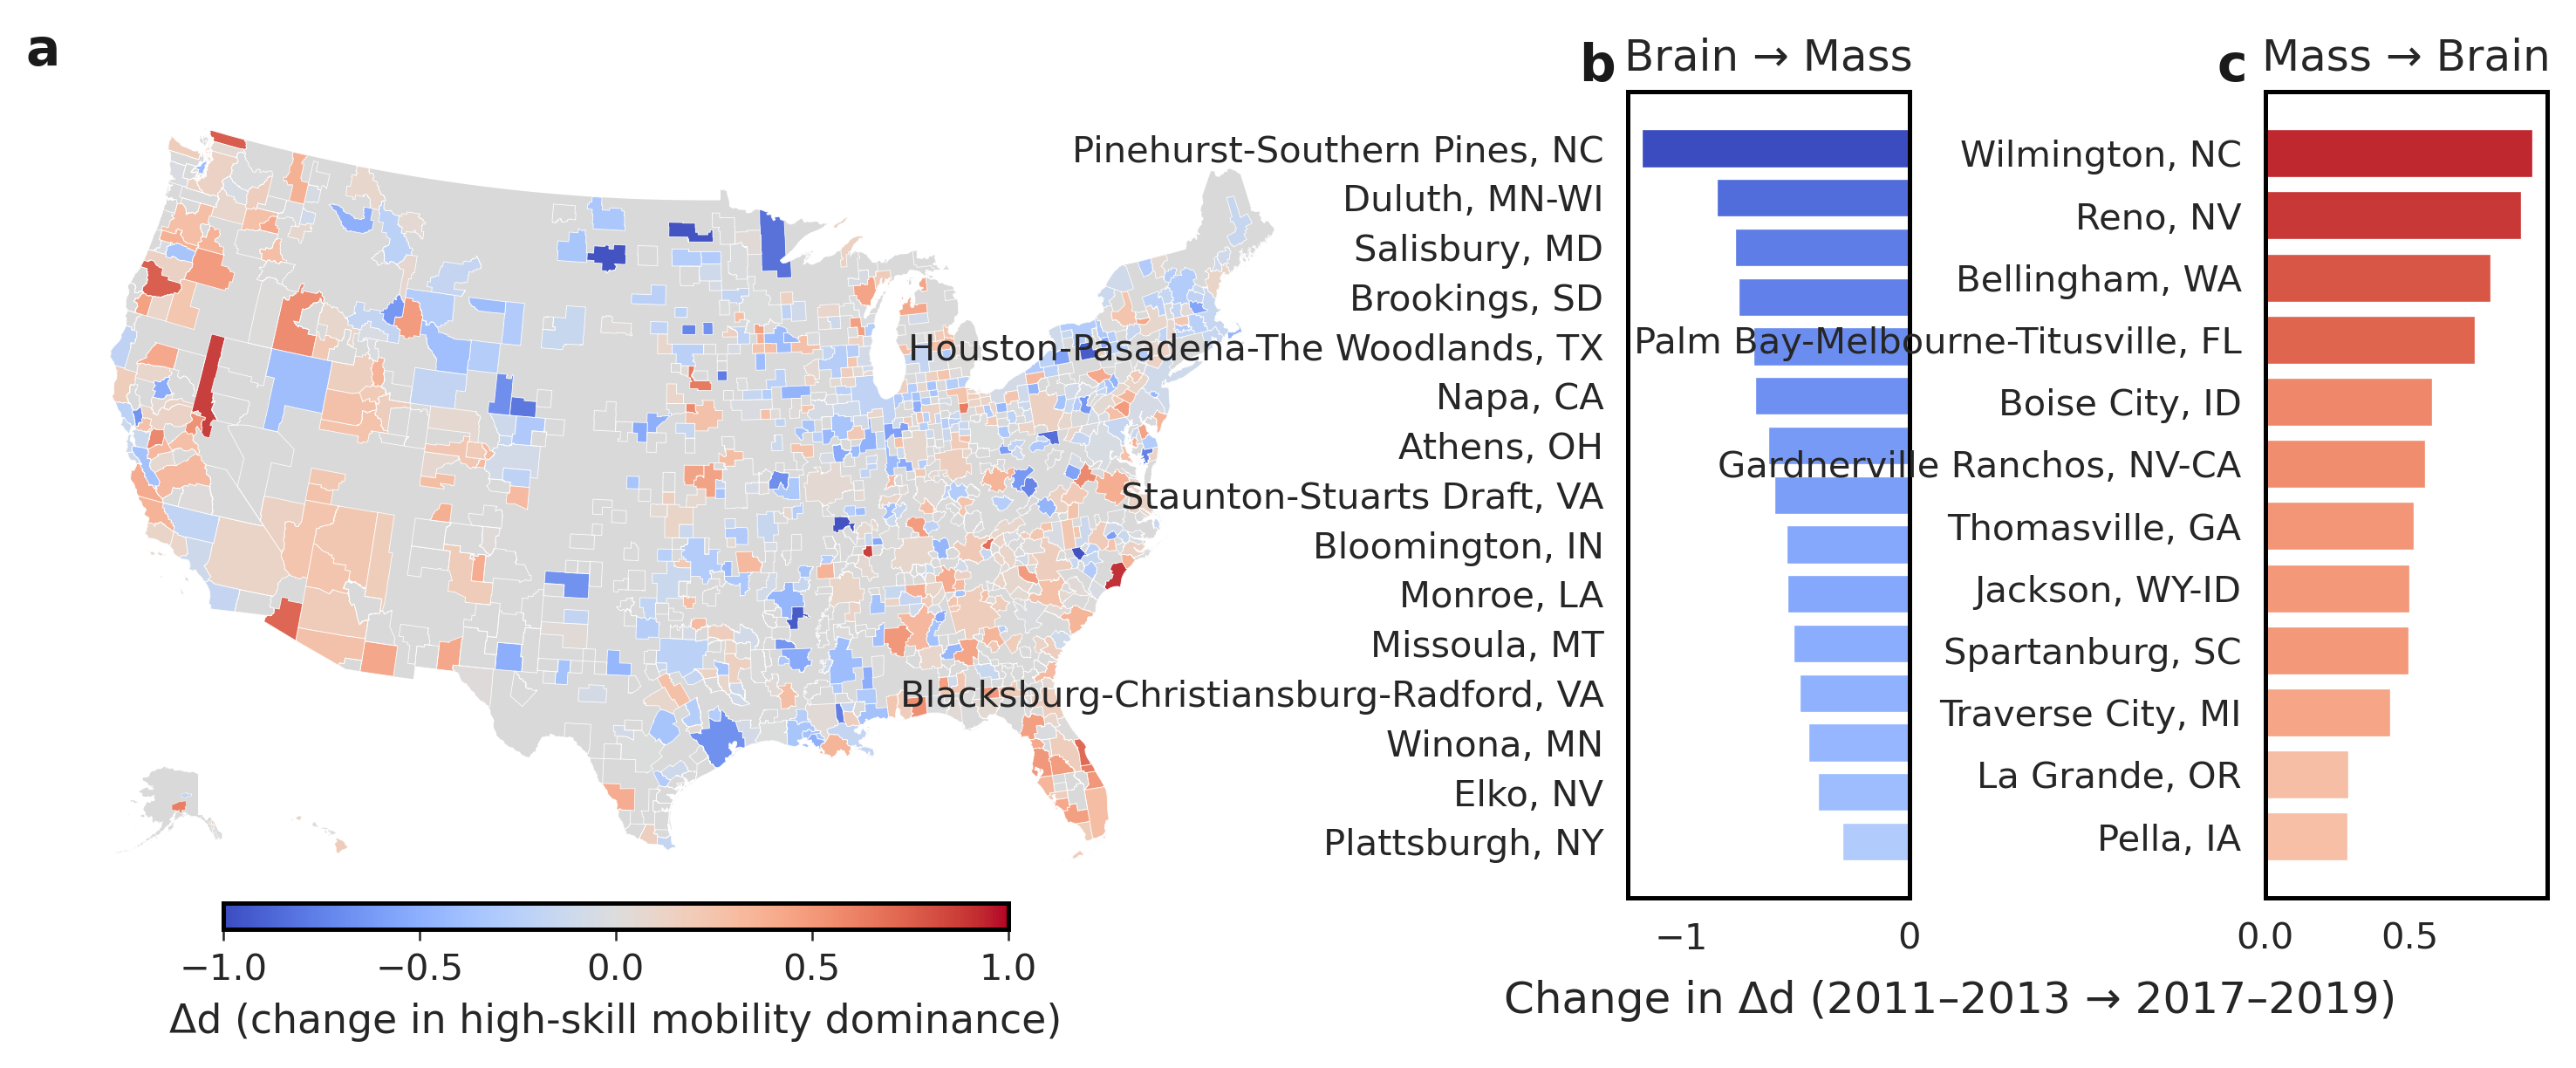

In [50]:
# colormap
norm = mcolors.Normalize(vmin=-1, vmax=1)
cmap = mpl.colormaps["coolwarm"]

# figure layout
fig, axes = plt.subplots(
    1, 3,
    figsize=(12, 4),
    gridspec_kw={"width_ratios": [5, 1, 1]},
    constrained_layout=False
)

fig.subplots_adjust(
    wspace=0.35    # increase horizontal spacing
)

ax_map = axes[0]
ax_barA = axes[1]
ax_barB = axes[2]

# ======================================================
#  MAIN CONUS MAP
# ======================================================

conus_outline.plot(
    color="#d9d9d9",
    linewidth=0,
    ax=ax_map,
    zorder=1,
    rasterized=True
)

conus.plot(
    column='d_change_2019',
    cmap=cmap,
    norm=norm,
    linewidth=0.2,
    edgecolor='white',
    ax=ax_map,
    legend=False,
    alpha=0.95,
    zorder=2,
    missing_kwds={"color": "none"},
    rasterized=True
)

ax_map.axis("off")
ax_map.set_title("")

# -------------------------------
# Alaska inset
# -------------------------------
ax_ak = inset_axes(
    ax_map, width="38%", height="38%",
    loc="lower left",
    bbox_to_anchor=(0.02, 0.03, 0.3, 0.3),
    bbox_transform=ax_map.transAxes
)
ax_ak.axis("off")

alaska_outline.plot(color="#d9d9d9", linewidth=0, ax=ax_ak, rasterized=True)
alaska.plot(
    column='d_change_2019',
    cmap=cmap,
    norm=norm,
    linewidth=0.1,
    edgecolor="white",
    ax=ax_ak,
    alpha=0.95,
    rasterized=True
)
ax_ak.set_xlim(-180, -129)
ax_ak.set_ylim(51, 72)

# -------------------------------
# Hawaii inset
# -------------------------------
ax_hi = inset_axes(
    ax_map, width="28%", height="28%",
    loc="lower left",
    bbox_to_anchor=(0.16, 0.02, 0.25, 0.25),
    bbox_transform=ax_map.transAxes
)
ax_hi.axis("off")

hawaii_outline.plot(color="#d9d9d9", linewidth=0, ax=ax_hi, rasterized=True)
hawaii.plot(
    column='d_change_2019',
    cmap=cmap,
    norm=norm,
    linewidth=0.1,
    edgecolor="white",
    ax=ax_hi,
    alpha=0.95,
    rasterized=True
)
ax_hi.set_xlim(-161, -154)
ax_hi.set_ylim(18, 23)


# ======================================================
# BARPLOT A (MASS → BRAIN)
# ======================================================

ax_barA.barh(
    group_a['name'],
    group_a['d_change'],
    color=cmap(norm(group_a['d_change']))
)
ax_barA.set_title("Brain → Mass")
ax_barA.set_xlabel("")


# ======================================================
# BARPLOT B (BRAIN → MASS)
# ======================================================

ax_barB.barh(
    group_b['name'],
    group_b['d_change'],
    color=cmap(norm(group_b['d_change']))
)
ax_barB.set_title("Mass → Brain")
ax_barB.set_xlabel("")


# get positions
posA = axes[1].get_position()
posB = axes[2].get_position()

# shift B right by +0.04 (adjust as needed)
axes[2].set_position([
    posB.x0 + 0.04,
    posB.y0,
    posB.width,
    posB.height
])

# SHARED X-LABEL FOR BARPLOTS ONLY
fig.text(
    0.75,       # horizontal center of barplots A+B
    0,       # vertical position (adjust)
    "Change in Δd (2011–2013 → 2017–2019)",
    ha='center',
    fontsize=12
)

# SHARED COLORBAR FOR ALL THREE SUBPLOTS
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar_ax = fig.add_axes([0.2, 0.08, 0.25, 0.025])

cbar = fig.colorbar(
    sm,
    cax=cbar_ax,
    orientation="horizontal",
    fraction=0.06,
    pad=0.12
)
cbar.set_label("Δd (change in high-skill mobility dominance)")

plots_l = ['a', 'b', 'c']

for ia, ax in enumerate(axes):
    x = -0.02
    y = 1.02

    if ia == 1:
        x = -0.17 
        y = 1
    elif ia == 2:
        x = -0.17 
        y = 1

    ax.text(
        x, y,
        plots_l[ia],
        color='k',
        ha='left',
        va='bottom',
        weight='bold',
        transform=ax.transAxes,
        fontsize=14
    )


plt.savefig(
    '../fig/si/si_pagerank_tempchanges_cbsa2_2019.png',
    bbox_inches='tight',
    dpi=300
)

plt.show()


In [51]:
group_b = d_pivot[(d_pivot['d_2011_2013'] <= -0.1) &
                  (d_pivot['d_2020_2022'] >=  0.1)].copy()

group_a = d_pivot[(d_pivot['d_2011_2013'] >=  0.1) &
                  (d_pivot['d_2020_2022'] <= -0.1)].copy()


cols = ['name', 'd_2011_2013', 'd_2020_2022', 'd_change']
group_a = group_a[cols].sort_values('d_change', ascending=False)
group_b = group_b[cols].sort_values('d_change', ascending=True)

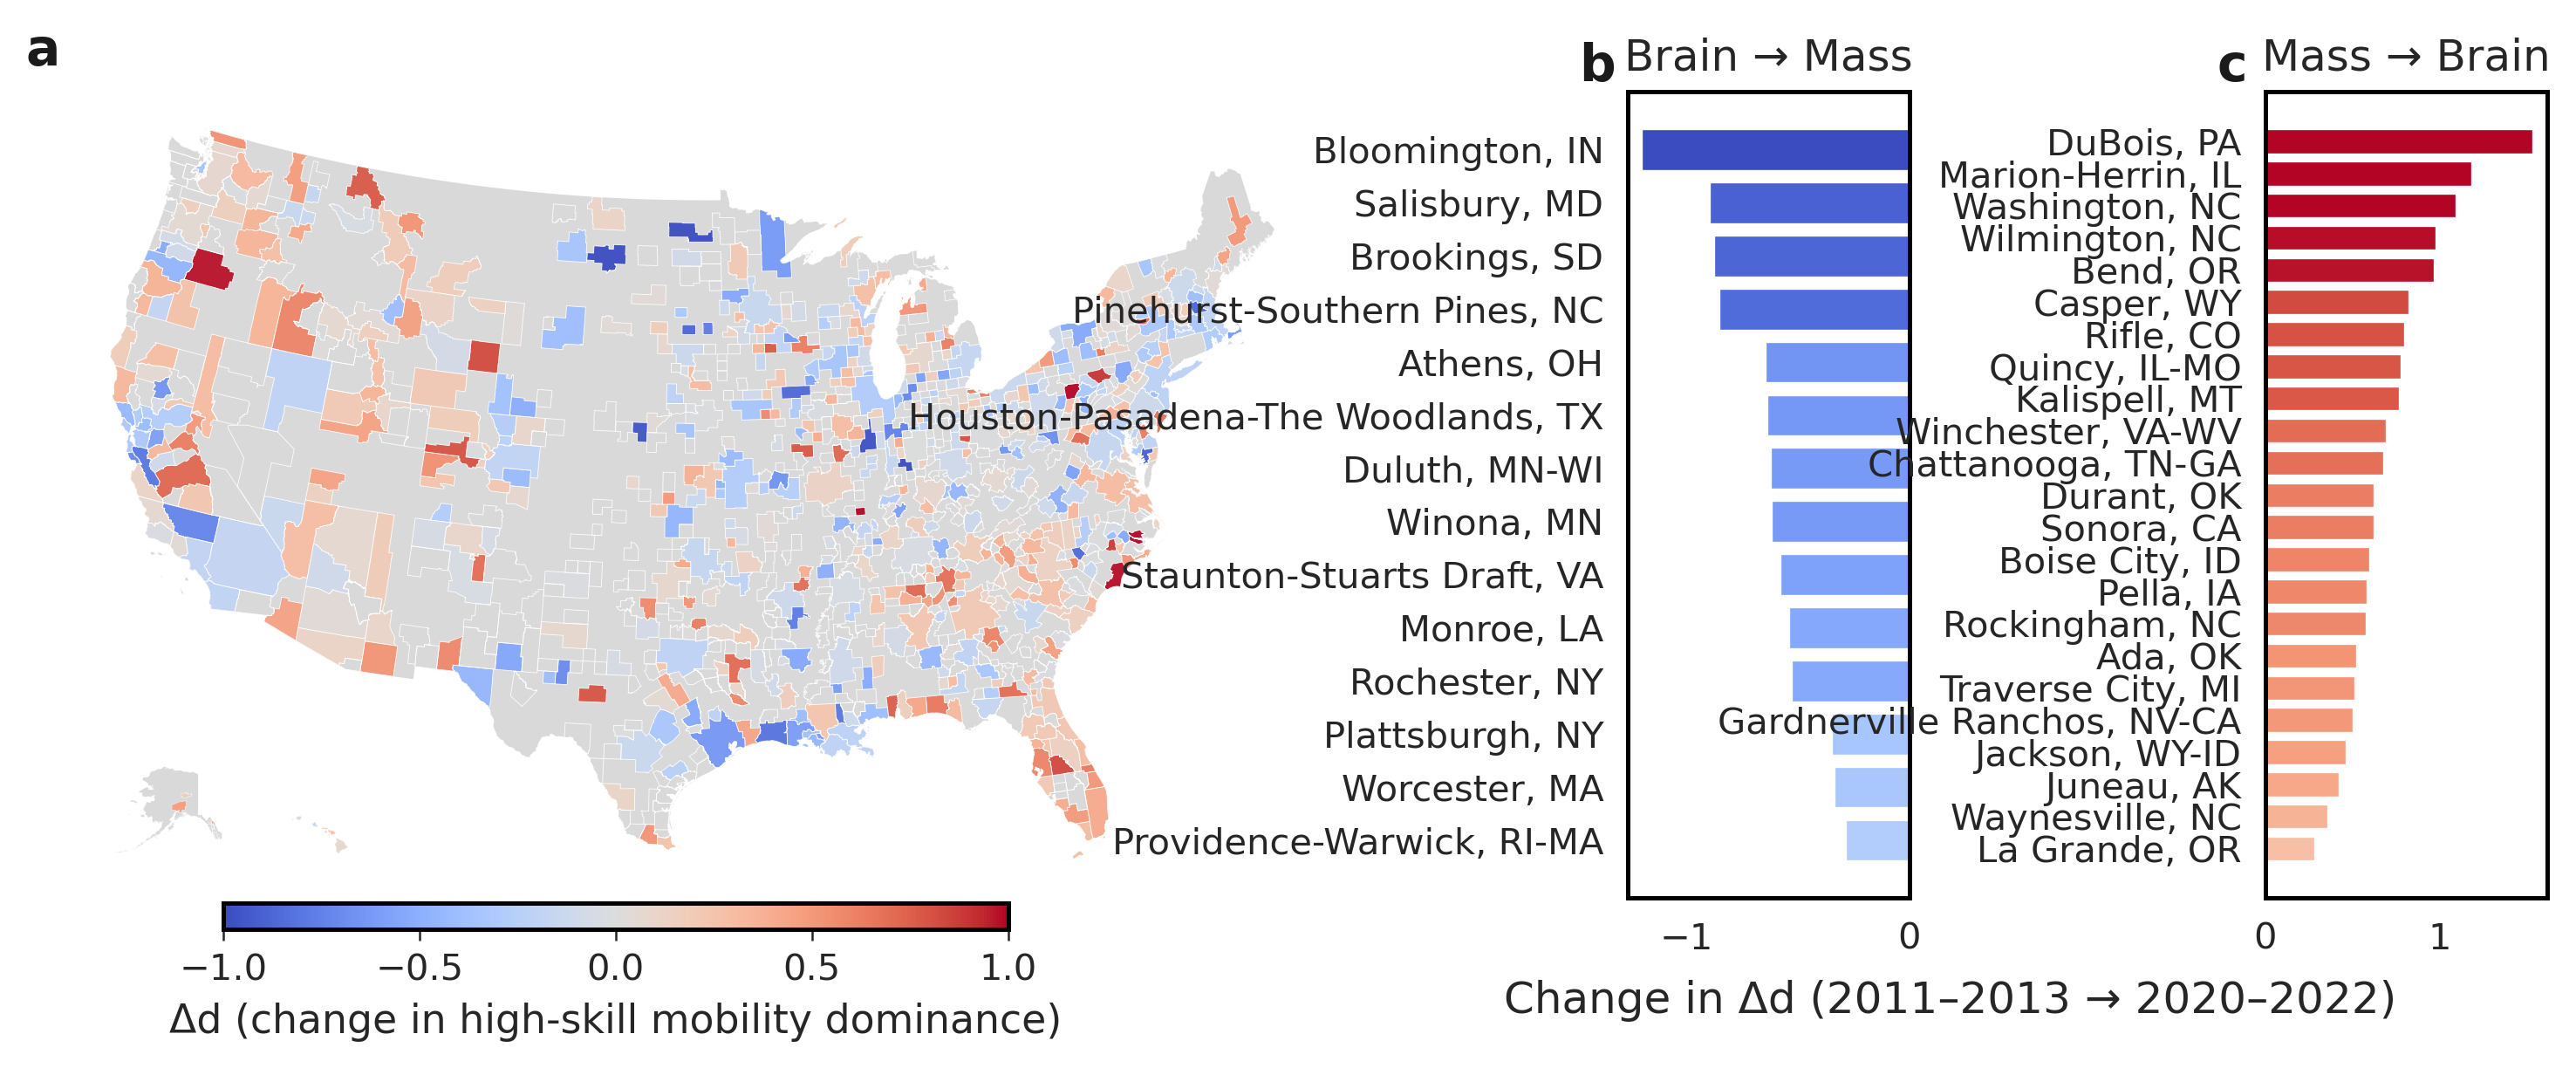

In [52]:
# colormap
norm = mcolors.Normalize(vmin=-1, vmax=1)
cmap = mpl.colormaps["coolwarm"]

# figure layout
fig, axes = plt.subplots(
    1, 3,
    figsize=(12, 4),
    gridspec_kw={"width_ratios": [5, 1, 1]},
    constrained_layout=False
)

fig.subplots_adjust(
    wspace=0.35    # increase horizontal spacing
)

ax_map = axes[0]
ax_barA = axes[1]
ax_barB = axes[2]

# ======================================================
#  MAIN CONUS MAP
# ======================================================

conus_outline.plot(
    color="#d9d9d9",
    linewidth=0,
    ax=ax_map,
    zorder=1,
    rasterized=True
)

conus.plot(
    column='d_change_2022',
    cmap=cmap,
    norm=norm,
    linewidth=0.2,
    edgecolor='white',
    ax=ax_map,
    legend=False,
    alpha=0.95,
    zorder=2,
    missing_kwds={"color": "none"},
    rasterized=True
)

ax_map.axis("off")
ax_map.set_title("")

# -------------------------------
# Alaska inset
# -------------------------------
ax_ak = inset_axes(
    ax_map, width="38%", height="38%",
    loc="lower left",
    bbox_to_anchor=(0.02, 0.03, 0.3, 0.3),
    bbox_transform=ax_map.transAxes
)
ax_ak.axis("off")

alaska_outline.plot(color="#d9d9d9", linewidth=0, ax=ax_ak, rasterized=True)
alaska.plot(
    column='d_change_2022',
    cmap=cmap,
    norm=norm,
    linewidth=0.1,
    edgecolor="white",
    ax=ax_ak,
    alpha=0.95,
    rasterized=True
)
ax_ak.set_xlim(-180, -129)
ax_ak.set_ylim(51, 72)

# -------------------------------
# Hawaii inset
# -------------------------------
ax_hi = inset_axes(
    ax_map, width="28%", height="28%",
    loc="lower left",
    bbox_to_anchor=(0.16, 0.02, 0.25, 0.25),
    bbox_transform=ax_map.transAxes
)
ax_hi.axis("off")

hawaii_outline.plot(color="#d9d9d9", linewidth=0, ax=ax_hi, rasterized=True)
hawaii.plot(
    column='d_change_2022',
    cmap=cmap,
    norm=norm,
    linewidth=0.1,
    edgecolor="white",
    ax=ax_hi,
    alpha=0.95,
    rasterized=True
)
ax_hi.set_xlim(-161, -154)
ax_hi.set_ylim(18, 23)


# ======================================================
# BARPLOT A (MASS → BRAIN)
# ======================================================

ax_barA.barh(
    group_a['name'],
    group_a['d_change'],
    color=cmap(norm(group_a['d_change']))
)
ax_barA.set_title("Brain → Mass")
ax_barA.set_xlabel("")


# ======================================================
# BARPLOT B (BRAIN → MASS)
# ======================================================

ax_barB.barh(
    group_b['name'],
    group_b['d_change'],
    color=cmap(norm(group_b['d_change']))
)
ax_barB.set_title("Mass → Brain")
ax_barB.set_xlabel("")


# get positions
posA = axes[1].get_position()
posB = axes[2].get_position()

# shift B right by +0.04 (adjust as needed)
axes[2].set_position([
    posB.x0 + 0.04,
    posB.y0,
    posB.width,
    posB.height
])

# SHARED X-LABEL FOR BARPLOTS ONLY
fig.text(
    0.75,       # horizontal center of barplots A+B
    0,       # vertical position (adjust)
    "Change in Δd (2011–2013 → 2020–2022)",
    ha='center',
    fontsize=12
)

# ======================================================
# SHARED COLORBAR FOR ALL THREE SUBPLOTS
# ======================================================
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar_ax = fig.add_axes([0.2, 0.08, 0.25, 0.025])

cbar = fig.colorbar(
    sm,
    cax=cbar_ax,
    orientation="horizontal",
    fraction=0.06,
    pad=0.12
)
cbar.set_label("Δd (change in high-skill mobility dominance)")

plots_l = ['a', 'b', 'c']

for ia, ax in enumerate(axes):
    x = -0.02
    y = 1.02

    if ia == 1:
        x = -0.17 
        y = 1
    elif ia == 2:
        x = -0.17 
        y = 1

    ax.text(
        x, y,
        plots_l[ia],
        color='k',
        ha='left',
        va='bottom',
        weight='bold',
        transform=ax.transAxes,
        fontsize=14
    )


plt.savefig(
    '../fig/si/si_pagerank_tempchanges_cbsa2_2022.png',
    bbox_inches='tight',
    dpi=300
)

plt.show()

In [53]:
hits_soc2_all=hits_soc2_all.merge(cbsa_gdf[['CBSA', 'name']])

In [54]:
# Make a copy so nothing gets overwritten
df = hits_soc2_all.copy()

# For safety, ensure pagerank is numeric
df["pagerank"] = pd.to_numeric(df["pagerank"], errors="coerce")

# Sort descending within each field and take top 20
top20 = (
    df.sort_values(["job_field", "pagerank"], ascending=[True, False])
      .groupby("job_field")
      .head(20)
)

# Create rank within each job field (1 = highest PageRank)
top20["rank_within_field"] = top20.groupby("job_field")["pagerank"].rank(
    method="first", ascending=False
).astype(int)

# Pivot into a wide table (columns = job fields, rows = 1..20)
table = (
    top20.pivot(
        index="rank_within_field",
        columns="job_field",
        values="name"   # or use df["name"] if you add names
    )
    .sort_index()
)

# (Optional) sort columns alphabetically
table = table.reindex(sorted(table.columns), axis=1)

table


job_field,Architecture & Engineering,Arts / Media / Design,Business & Finance,Computer & Math,Education / Training,Healthcare Practitioners,Legal,Management,Sales,Sciences,Social Services
rank_within_field,,,,,,,,,,,
1,"San Francisco-Oakland-Fremont, CA","New York-Newark-Jersey City, NY-NJ","New York-Newark-Jersey City, NY-NJ","San Francisco-Oakland-Fremont, CA","San Francisco-Oakland-Fremont, CA","Dallas-Fort Worth-Arlington, TX","New York-Newark-Jersey City, NY-NJ","New York-Newark-Jersey City, NY-NJ","New York-Newark-Jersey City, NY-NJ","New York-Newark-Jersey City, NY-NJ","San Francisco-Oakland-Fremont, CA"
2,"San Jose-Sunnyvale-Santa Clara, CA","Los Angeles-Long Beach-Anaheim, CA","San Francisco-Oakland-Fremont, CA","San Jose-Sunnyvale-Santa Clara, CA","New York-Newark-Jersey City, NY-NJ","New York-Newark-Jersey City, NY-NJ","Washington-Arlington-Alexandria, DC-VA-MD-WV","San Francisco-Oakland-Fremont, CA","San Francisco-Oakland-Fremont, CA","San Francisco-Oakland-Fremont, CA","Los Angeles-Long Beach-Anaheim, CA"
3,"New York-Newark-Jersey City, NY-NJ","San Francisco-Oakland-Fremont, CA","Los Angeles-Long Beach-Anaheim, CA","New York-Newark-Jersey City, NY-NJ","San Jose-Sunnyvale-Santa Clara, CA","Chicago-Naperville-Elgin, IL-IN","San Francisco-Oakland-Fremont, CA","Los Angeles-Long Beach-Anaheim, CA","Los Angeles-Long Beach-Anaheim, CA","Los Angeles-Long Beach-Anaheim, CA","New York-Newark-Jersey City, NY-NJ"
4,"Washington-Arlington-Alexandria, DC-VA-MD-WV","Chicago-Naperville-Elgin, IL-IN","Chicago-Naperville-Elgin, IL-IN","Seattle-Tacoma-Bellevue, WA","Washington-Arlington-Alexandria, DC-VA-MD-WV","Los Angeles-Long Beach-Anaheim, CA","Los Angeles-Long Beach-Anaheim, CA","Chicago-Naperville-Elgin, IL-IN","Chicago-Naperville-Elgin, IL-IN","Washington-Arlington-Alexandria, DC-VA-MD-WV","San Jose-Sunnyvale-Santa Clara, CA"
5,"Boston-Cambridge-Newton, MA-NH","Washington-Arlington-Alexandria, DC-VA-MD-WV","Washington-Arlington-Alexandria, DC-VA-MD-WV","Washington-Arlington-Alexandria, DC-VA-MD-WV","Los Angeles-Long Beach-Anaheim, CA","San Francisco-Oakland-Fremont, CA","Chicago-Naperville-Elgin, IL-IN","Boston-Cambridge-Newton, MA-NH","Boston-Cambridge-Newton, MA-NH","Boston-Cambridge-Newton, MA-NH","Washington-Arlington-Alexandria, DC-VA-MD-WV"
6,"Los Angeles-Long Beach-Anaheim, CA","Boston-Cambridge-Newton, MA-NH","Dallas-Fort Worth-Arlington, TX","Boston-Cambridge-Newton, MA-NH","Boston-Cambridge-Newton, MA-NH","Philadelphia-Camden-Wilmington, PA-NJ-DE-MD","Atlanta-Sandy Springs-Roswell, GA","Dallas-Fort Worth-Arlington, TX","Dallas-Fort Worth-Arlington, TX","Chicago-Naperville-Elgin, IL-IN","San Diego-Chula Vista-Carlsbad, CA"
7,"Seattle-Tacoma-Bellevue, WA","Dallas-Fort Worth-Arlington, TX","Boston-Cambridge-Newton, MA-NH","Los Angeles-Long Beach-Anaheim, CA","Chicago-Naperville-Elgin, IL-IN","Nashville-Davidson--Murfreesboro--Franklin, TN","Dallas-Fort Worth-Arlington, TX","Washington-Arlington-Alexandria, DC-VA-MD-WV","San Jose-Sunnyvale-Santa Clara, CA","San Jose-Sunnyvale-Santa Clara, CA","Chicago-Naperville-Elgin, IL-IN"
8,"Chicago-Naperville-Elgin, IL-IN","Atlanta-Sandy Springs-Roswell, GA","Atlanta-Sandy Springs-Roswell, GA","Austin-Round Rock-San Marcos, TX","Seattle-Tacoma-Bellevue, WA","Atlanta-Sandy Springs-Roswell, GA","Boston-Cambridge-Newton, MA-NH","San Jose-Sunnyvale-Santa Clara, CA","Austin-Round Rock-San Marcos, TX","Atlanta-Sandy Springs-Roswell, GA","Denver-Aurora-Centennial, CO"
9,"Atlanta-Sandy Springs-Roswell, GA","San Jose-Sunnyvale-Santa Clara, CA","San Jose-Sunnyvale-Santa Clara, CA","Chicago-Naperville-Elgin, IL-IN","Philadelphia-Camden-Wilmington, PA-NJ-DE-MD","Washington-Arlington-Alexandria, DC-VA-MD-WV","San Jose-Sunnyvale-Santa Clara, CA","Atlanta-Sandy Springs-Roswell, GA","Atlanta-Sandy Springs-Roswell, GA","Seattle-Tacoma-Bellevue, WA","Philadelphia-Camden-Wilmington, PA-NJ-DE-MD"


In [55]:
df_wide = hits_soc2_all.pivot_table(
    index="CBSA",
    columns="job_field",
    values="pagerank"
)

df_wide = df_wide.dropna()

corr_spearman = df_wide.corr(method="spearman")


In [56]:
corr_spearman.round(2)


job_field,Architecture & Engineering,Arts / Media / Design,Business & Finance,Computer & Math,Education / Training,Healthcare Practitioners,Legal,Management,Sales,Sciences,Social Services
job_field,,,,,,,,,,,
Architecture & Engineering,1.00,0.88,0.84,0.88,0.90,0.76,0.76,0.86,0.88,0.71,0.60
Arts / Media / Design,0.88,1.00,0.93,0.94,0.93,0.86,0.76,0.95,0.93,0.75,0.67
Business & Finance,0.84,0.93,1.00,0.94,0.92,0.87,0.77,0.97,0.94,0.76,0.70
Computer & Math,0.88,0.94,0.94,1.00,0.93,0.84,0.74,0.95,0.94,0.78,0.67
Education / Training,0.90,0.93,0.92,0.93,1.00,0.82,0.75,0.93,0.90,0.74,0.65
Healthcare Practitioners,0.76,0.86,0.87,0.84,0.82,1.00,0.70,0.89,0.84,0.72,0.61
Legal,0.76,0.76,0.77,0.74,0.75,0.70,1.00,0.78,0.78,0.70,0.60
Management,0.86,0.95,0.97,0.95,0.93,0.89,0.78,1.00,0.96,0.77,0.70
Sales,0.88,0.93,0.94,0.94,0.90,0.84,0.78,0.96,1.00,0.76,0.70


In [57]:
def format_bottom_colorbar(cbar, label):
    # identical tick behaviour
    cbar.ax.tick_params(
        axis="x",
        labelsize=9,
        length=4,
        width=0.6,
        pad=3
    )

    # identical label formatting
    cbar.set_label(label, fontsize=10, labelpad=4)

    # identical spine appearance
    for side in ["bottom", "top"]:
        cbar.ax.spines[side].set_visible(True)
        cbar.ax.spines[side].set_linewidth(0.6)

    # no left/right spines (keeps consistent)
    cbar.ax.spines["left"].set_visible(False)
    cbar.ax.spines["right"].set_visible(False)

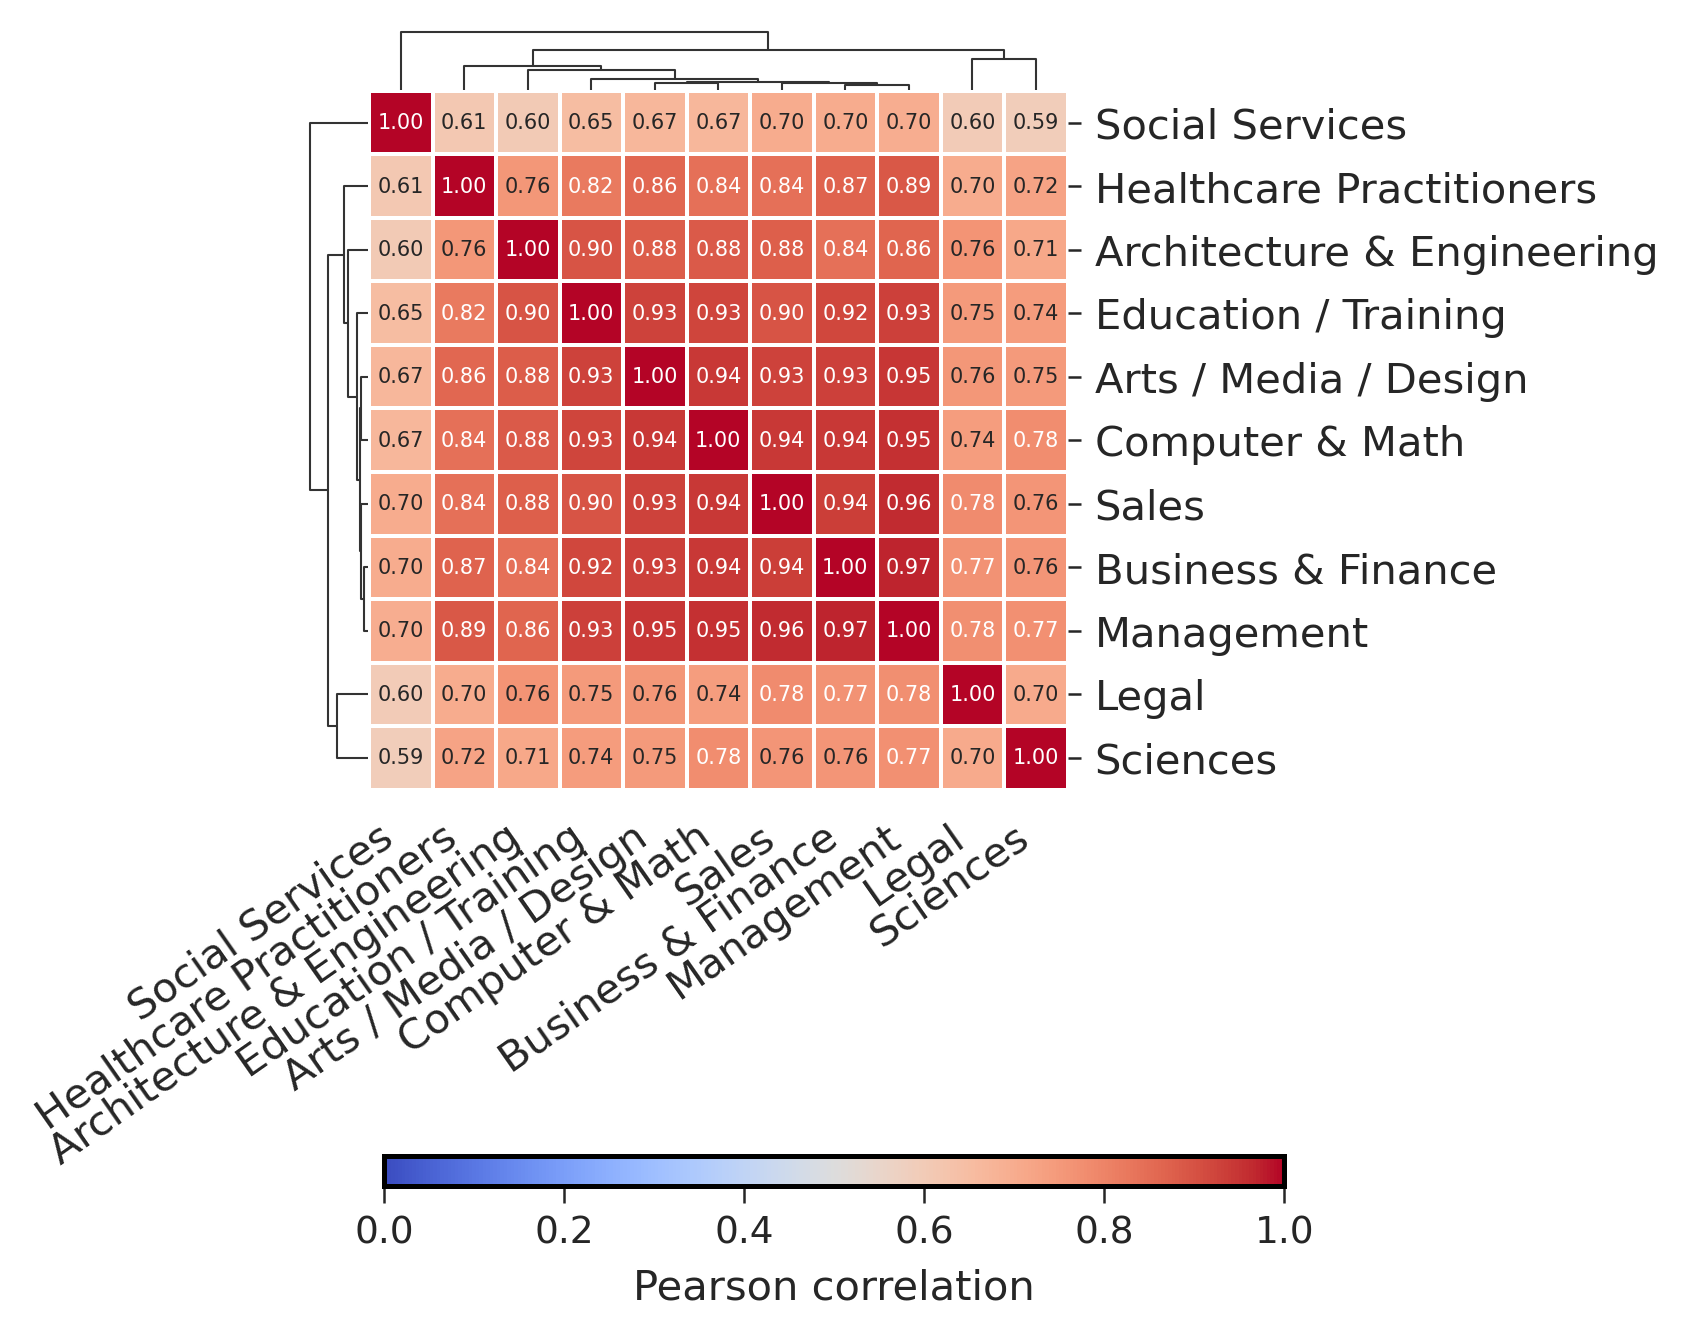

In [58]:
g = sns.clustermap(
    corr_spearman,
    cmap="coolwarm",
    method="average", 
    metric="euclidean",
    linewidths=0.5,
    figsize=(5, 5),
    vmin=0, vmax=1,
    annot=True,
    cbar_pos=None,
    dendrogram_ratio=(0.08, 0.08),
    fmt=".2f",
    annot_kws={"size": 5}
)

fig = g.fig

left = 0.08
width = 0.6
bottom = 0.2
height = 0.02
cax = fig.add_axes([left, bottom, width, height])

# Pearson ScalarMappable
pearson_norm = plt.Normalize(vmin=0, vmax=1)
sm = plt.cm.ScalarMappable(norm=pearson_norm, cmap="coolwarm")

g.ax_heatmap.set_xticklabels(g.ax_heatmap.get_xmajorticklabels(), rotation=35, ha="right")
g.ax_heatmap.set_xlabel("")
g.ax_heatmap.set_ylabel("")

cbar = fig.colorbar(
    sm,
    cax=cax,
    orientation="horizontal",
)
format_bottom_colorbar(cbar, "Pearson correlation")

plt.savefig(
    '../fig/si/si_jobfields_corr_cbsa2.pdf',
    bbox_inches='tight',
    dpi=300
)

plt.show()